# **Прогнозирование вероятности отчисления студентов на основе их характеристик**



Абакаров Мурад - БСТ241


**Описание работы и ее цель:**

В рамках проекта по анализу данных используется датасет Student Dropout Prediction Dataset, содержащий информацию о демографических, социально-экономических и академических характеристиках студентов.

Датасет включает 10 000 наблюдений и 19 признаков. Каждое наблюдение соответствует отдельному студенту, для кторого представлены его индивидуальные характеристики.

**Цель работы**— исследовать взаимосвязь характеристик студентов с вероятностью их отчисления и построить модель бинарной логистической регрессии для прогнозирования данной вероятности.

В качетсве целевой переменной возьмем столбец **Dropout** - это категориальный бинарный признак, которой принимает значения:

 0 -  если студента не отчислили

 1 -  если студента отчислили.

 **Источник данных**: https://www.kaggle.com/datasets/meharshanali/student-dropout-prediction-dataset?select=student_dropout_dataset_v3.csv.

## **Содержание**



# **Часть 1. Разведочный анализ**

## **1. Импортирование библиотек и загрузка датасета**

In [ ]:

import kagglehub
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    log_loss,
    roc_curve
)


In [ ]:
path = kagglehub.dataset_download("meharshanali/student-dropout-prediction-dataset",
                                  path = 'student_dropout_dataset_v3.csv')
df = pd.read_csv(path)
df.head()

Using Colab cache for faster access to the 'student-dropout-prediction-dataset' dataset.


,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0


## **2. Описание признаков**

### **2.1 Название признаков и их описание:**


В исходном датасете представлены 19 признаков, включающих количественные и категориальные переменные. Ниже приведены их описания, технические форматы и статистические типы.

| Признак | Описание | Формат данных | Статистический тип |
|---|---|---|---|
| `Student_ID` | Уникальный идентификатор студента | int64 | Номинальный, идентификатор |
| `Age` | Возраст студента | float64 | Количественный непрерывный |
| `Gender` | Пол студента | object | Категориальный бинарный |
| `Family_Income` | Семейный доход студента | float64 | Количественный непрерывный |
| `Internet_Access` | Наличие доступа к интернету | object | Категориальный бинарный |
| `Study_Hours_per_Day` | Среднее количество часов учёбы в день | float64 | Количественный непрерывный |
| `Attendance_Rate` | Процент посещаемости занятий | float64 | Количественный непрерывный |
| `Assignment_Delay_Days` | Задержка сдачи заданий в днях | int64 | Количественный дискретный |
| `Travel_Time_Minutes` | Время на дорогу в минутах | float64 | Количественный непрерывный |
| `Part_Time_Job` | Наличие подработки | object | Категориальный бинарный |
| `Scholarship` | Наличие стипендии | object | Категориальный бинарный |
| `Stress_Index` | Индекс уровня стресса студента | float64 | Количественный непрерывный |
| `GPA` | Показатель академической успеваемости | float64 | Количественный непрерывный |
| `Semester_GPA` | Средний балл за семестр | float64 | Количественный непрерывный |
| `CGPA` | Накопленный средний балл успеваемости | float64 | Количественный непрерывный |
| `Semester` | Год обучения студента | object | Категориальный порядковый |
| `Department` | Направление обучения | object | Категориальный номинальный |
| `Parental_Education` | Уровень образования родителей | object | Категориальный порядковый |
| `Dropout` | Факт отчисления студента (0 — нет, 1 — да) | int64 | Категориальный бинарный, целевой |



### **2.2 Формат данных каждого признака**

In [ ]:
df_types = df.dtypes
df_types.name = 'Формат данных'
df_types

,Формат данных
Student_ID,int64
Age,float64
Gender,object
Family_Income,float64
Internet_Access,object
Study_Hours_per_Day,float64
Attendance_Rate,float64
Assignment_Delay_Days,int64
Travel_Time_Minutes,float64
Part_Time_Job,object


## **3. Пропуски и дубликаты**

### **3.1 Проверка на наличе пропусков в данных**

In [ ]:
# Проверка пропусков в столбцах
df_isna = df.isna().sum()
df_isna.name = 'Пропуски в даннных'
df_isna

,Пропуски в даннных
Student_ID,0
Age,0
Gender,0
Family_Income,500
Internet_Access,0
Study_Hours_per_Day,500
Attendance_Rate,0
Assignment_Delay_Days,0
Travel_Time_Minutes,0
Part_Time_Job,0


In [ ]:
#Столбцы с пропусками
df_isna[df_isna > 0]

,Пропуски в даннных
Family_Income,500
Study_Hours_per_Day,500
Stress_Index,500
Parental_Education,511


### **3.2 Проверка полных дубликатов в данных**

In [ ]:
# Наличине полных дубликатов в данных
if df.duplicated().sum() == 0:
  print('Полных дубликатов в данных нет')
else:
  print(f'Всего полных дубликатов в данных {df.duplicated().sum()}')

Полных дубликатов в данных нет


### **3.3 Заполенение пропусков на подходящие МЦТ**

Text(0, 0.5, 'Частота')

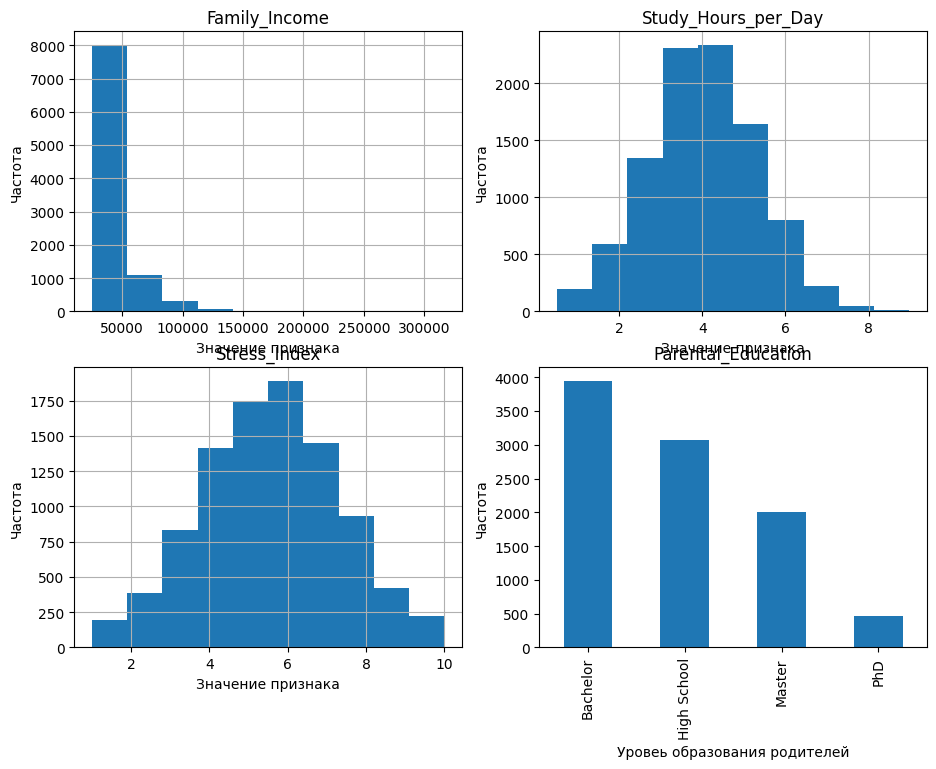

In [ ]:
# Прежде чем делать заполянть пропуски посмотрим на распределения пропущеных данных
columns = ['Family_Income', 'Study_Hours_per_Day', 'Stress_Index']

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

for i, column in enumerate(columns):
  df[column].hist(ax=axes[i])
  axes[i].set_title(column)
  axes[i].set_xlabel('Значение признака')
  axes[i].set_ylabel('Частота')

df['Parental_Education'].value_counts().plot(kind='bar', ax=axes[3])
axes[3].set_title('Parental_Education')
axes[3].set_xlabel('Уровеь образования родителей')
axes[3].set_ylabel('Частота')


#### **Заменим наши в пропуски в данных на их соотвествующие МЦТ, учитывая типы признаков и характер их распределений:**

**Family_Income** — заменим пропуски медианным значением, поскольку распределение доходов имеет выраженную правостороннюю асимметрию и содержит большие значения, которые могут существенно влиять на среднее.

**Study_Hours_per_Day** — заменим пропуски средним, поскольку распределение близко к симметричному, без заметных экстремальных значений.

**Stress_Index** — заменим пропуски средним арифметическим, поскольку распределение индекса стресса визуально близко к симметричному, без выраженной асимметрии.

**Parental_Education** — заменим пропуски модальным значением, поскольку признак является категориальным. Мода позволяет заполнить пропуски наиболее часто встречающейся категорией образования родителей.

### **3.4 Создадим новый датасет без пропусков и дубликатов**

In [ ]:
df_clean = df.copy()

df_clean['Family_Income'] = df_clean['Family_Income'].fillna(df['Family_Income'].median())
df_clean['Study_Hours_per_Day'] = df_clean['Study_Hours_per_Day'].fillna(df['Study_Hours_per_Day'].mean())
df_clean['Stress_Index'] = df_clean['Stress_Index'].fillna(df_clean['Stress_Index'].mean())
df_clean['Parental_Education'] = df_clean['Parental_Education'].fillna(df_clean['Parental_Education'].mode()[0])

print('Осталось пропусков:', df_clean.isna().sum().sum())
print('Осталось полных дубликатов:', df_clean.duplicated().sum())
print('Количество наблюдений:', len(df_clean))

Осталось пропусков: 0
Осталось полных дубликатов: 0
Количество наблюдений: 10000


### Вывод по обработке пропусков и дубликатов

 В исходном датасете обнаружены пропуски в четырёх признаках: **Family_Income, Study_Hours_per_Day, Stress_Index и Parental_Education**.
Пропущенные значения заменены соответствующими мерами центральной тенденции с учётом типов признаков и характера их распределений.
Полных дубликатов в исходном датасете не обнаружено.
После обработки пропуски и полные дубликаты отсутствуют. Количество наблюдений осталось неизменным — 10 000.

## **4. Выбросы**

### **4.1. Построение диаграмм boxplot для количественных признаков**

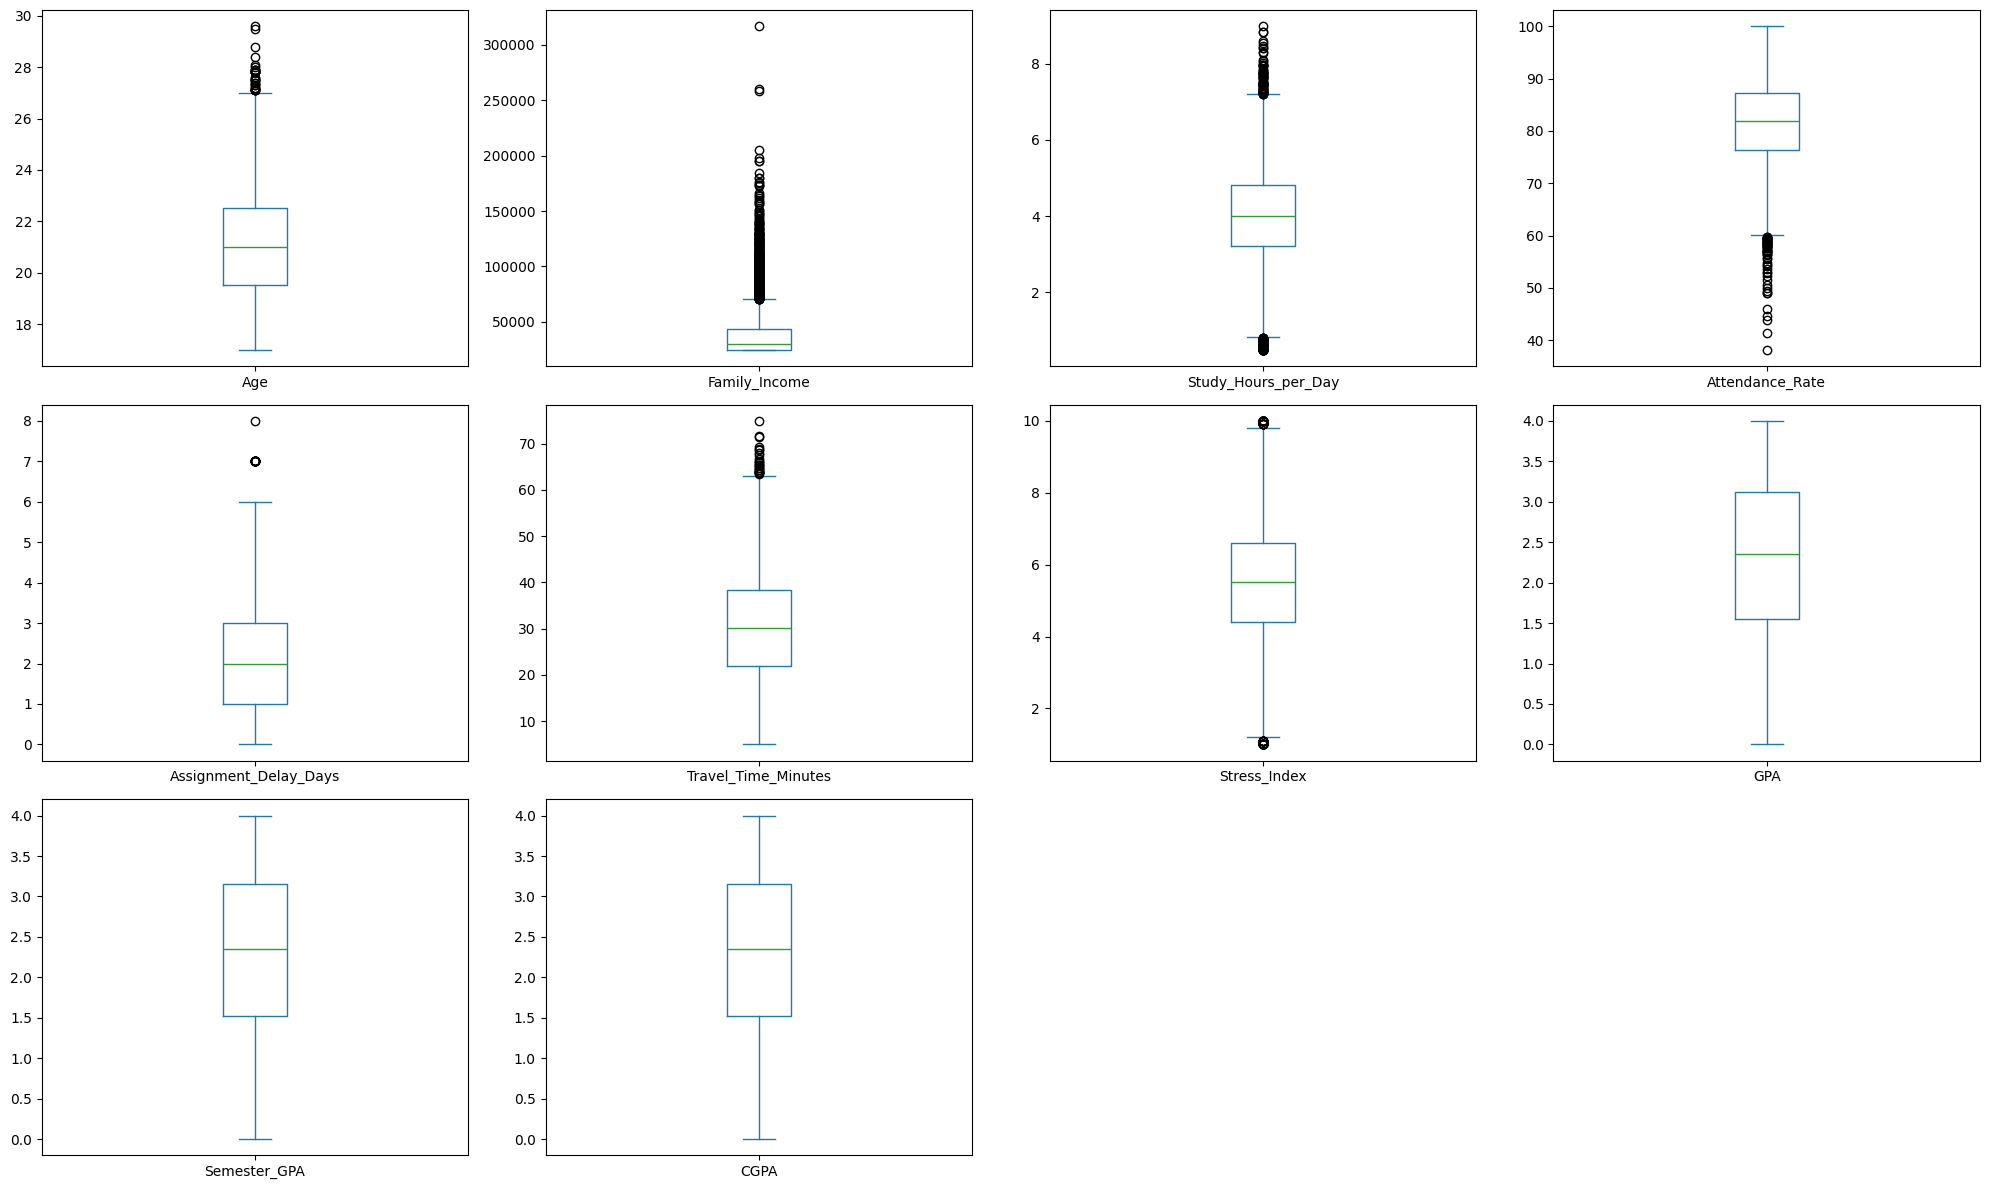

In [ ]:
numeric_columns = df_clean.select_dtypes(include=['int64', 'float64']).columns.drop(['Student_ID', 'Dropout'])

df_clean[numeric_columns].plot(
    kind='box',
    subplots=True,
    layout=(3, 4),
    figsize=(20, 12),
    sharey=False
)

plt.tight_layout()
plt.show()

### **4.2 Удаление выбросов методом 3-стандартных отклоненений**

Применим метод трёх стандартных отклонений к признаку Study_Hours_per_Day, распределение которого визуально близко к симметричному. Удалим наблюдения, значения которых отклоняются от среднего более чем на три стандартных отклонения

In [ ]:
column = 'Study_Hours_per_Day'
N = 3
mean = df_clean[column].mean()
std = df_clean[column].std()

lower_limit = mean - 3 * std
upper_limit = mean + 3 * std

df_std = df_clean[df_clean[column].between(lower_limit, upper_limit)].copy()
print(f'Удалено наблюдений после использования метода 3 стандартных отклонений: {np.abs(len(df_std) - len(df_clean))}')


Удалено наблюдений после использования метода 3 стандартных отклонений: 20


In [ ]:
column = 'Family_Income'

Q1 = df_std[column].quantile(0.25)
Q3 = df_std[column].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df_final = df_std[df_std[column].between(lower_limit, upper_limit)].copy()
print(f'Удалено наблюдений: {len(df_std) - len(df_final)}')
print(f'Итоговое количество наблюдений: {len(df_final)}')
print(f'Общая доля удалённых наблюдений: {(1 - len(df_final) / len(df_clean)) * 100:.2f}%')

Удалено наблюдений: 682
Итоговое количество наблюдений: 9298
Общая доля удалённых наблюдений: 7.02%


### **4.3 На всякий случай, проверим не нарушилось ли соотношенение классов целевой перемнной, после удаления выбросов**

In [ ]:
print(f'Соотношение классов до удаления выбросов')
print(df_clean['Dropout'].value_counts(normalize=True))

print(f'\nСоотношение классов после удаления выбросов')
print(df_final['Dropout'].value_counts(normalize=True))

Соотношение классов до удаления выбросов
Dropout
0    0.7646
1    0.2354
Name: proportion, dtype: float64

Соотношение классов после удаления выбросов
Dropout
0    0.763713
1    0.236287
Name: proportion, dtype: float64


### Вывод по обработке выбросов

С помощью диаграмм размаха были исследованы количественные признаки на наличие потенциальных выбросов. Наиболее заметные экстремальные значения наблюдаются, в частности, у **Family_Income** и **Study_Hours_per_Day**.
Для признака **Study_Hours_per_Day**, распределение которого близко к симметричному, применён метод трёх стандартных отклонений. В результате удалено **20 наблюдений**.
Для признака Family_Income, характеризующегося правосторонней асимметрией, применён метод межквартильного размаха (1,5xIQR). Дополнительно удалено **682 наблюдения**.
 Всего исключено **7,02%** наблюдений. Итоговая выборка содержит **9298 студентов**.
Доля отчисленных студентов изменилась незначительно: с **23,54% до 23,63%**. Следовательно, очистка практически не повлияла на соотношение классов целевой переменной `Dropout`.


## **5. Визуализация**

### **5.1. Гистограммы количественных признаков**

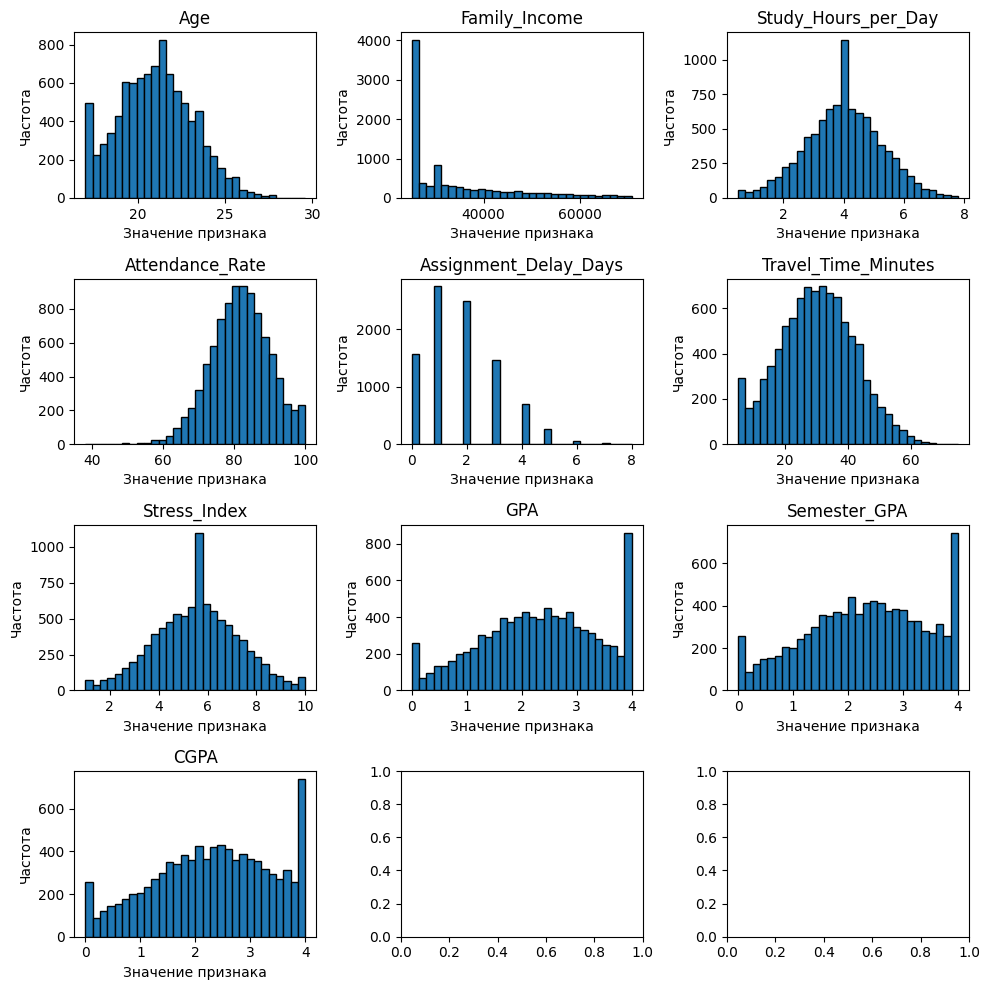

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    axes[i].hist(df_final[col], bins=30, edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Значение признака')
    axes[i].set_ylabel('Частота')


plt.tight_layout()
plt.show()



### Выводы по распределениям:

- **Age:** распределение возраста близко к колоколообразному. Большинство студентов имеют возраст примерно от 19 до 24 лет.
- **Family_Income:** распределение имеет выраженную правостороннюю асимметрию. Основная масса наблюдений сосредоточена в области относительно невысоких доходов.
- **Study_Hours_per_Day:** распределение приблизительно симметрично, большинство студентов занимается около 3–5 часов в день. Выраженный пик около 4 часов может быть частично обусловлен заполнением пропусков средним значением.
- **Attendance_Rate:** распределение характеризуется концентрацией наблюдений в области высокой посещаемости — преимущественно около 75–90%. Присутствует левый хвост, соответствующий студентам с низкой посещаемостью.
- **Assignment_Delay_Days:** распределение дискретное. Чаще всего задержка сдачи заданий составляет от 0 до 3 дней, а продолжительные задержки встречаются значительно реже.
- **Travel_Time_Minutes:** распределение близко к симметричному, с наибольшей концентрацией наблюдений около 25–40 минут.
- **Stress_Index:** значения сосредоточены преимущественно в средней части шкалы, примерно около 4–7 баллов. Заметный пик в центре распределения может быть связан с заменой пропусков средним.
- **GPA, Semester_GPA и CGPA:** все три показателя принимают значения от 0 до 4. Наблюдаются студенты с различным уровнем академической успеваемости.


### **5.2. Столбчатые диаграммы категориальных признаков**

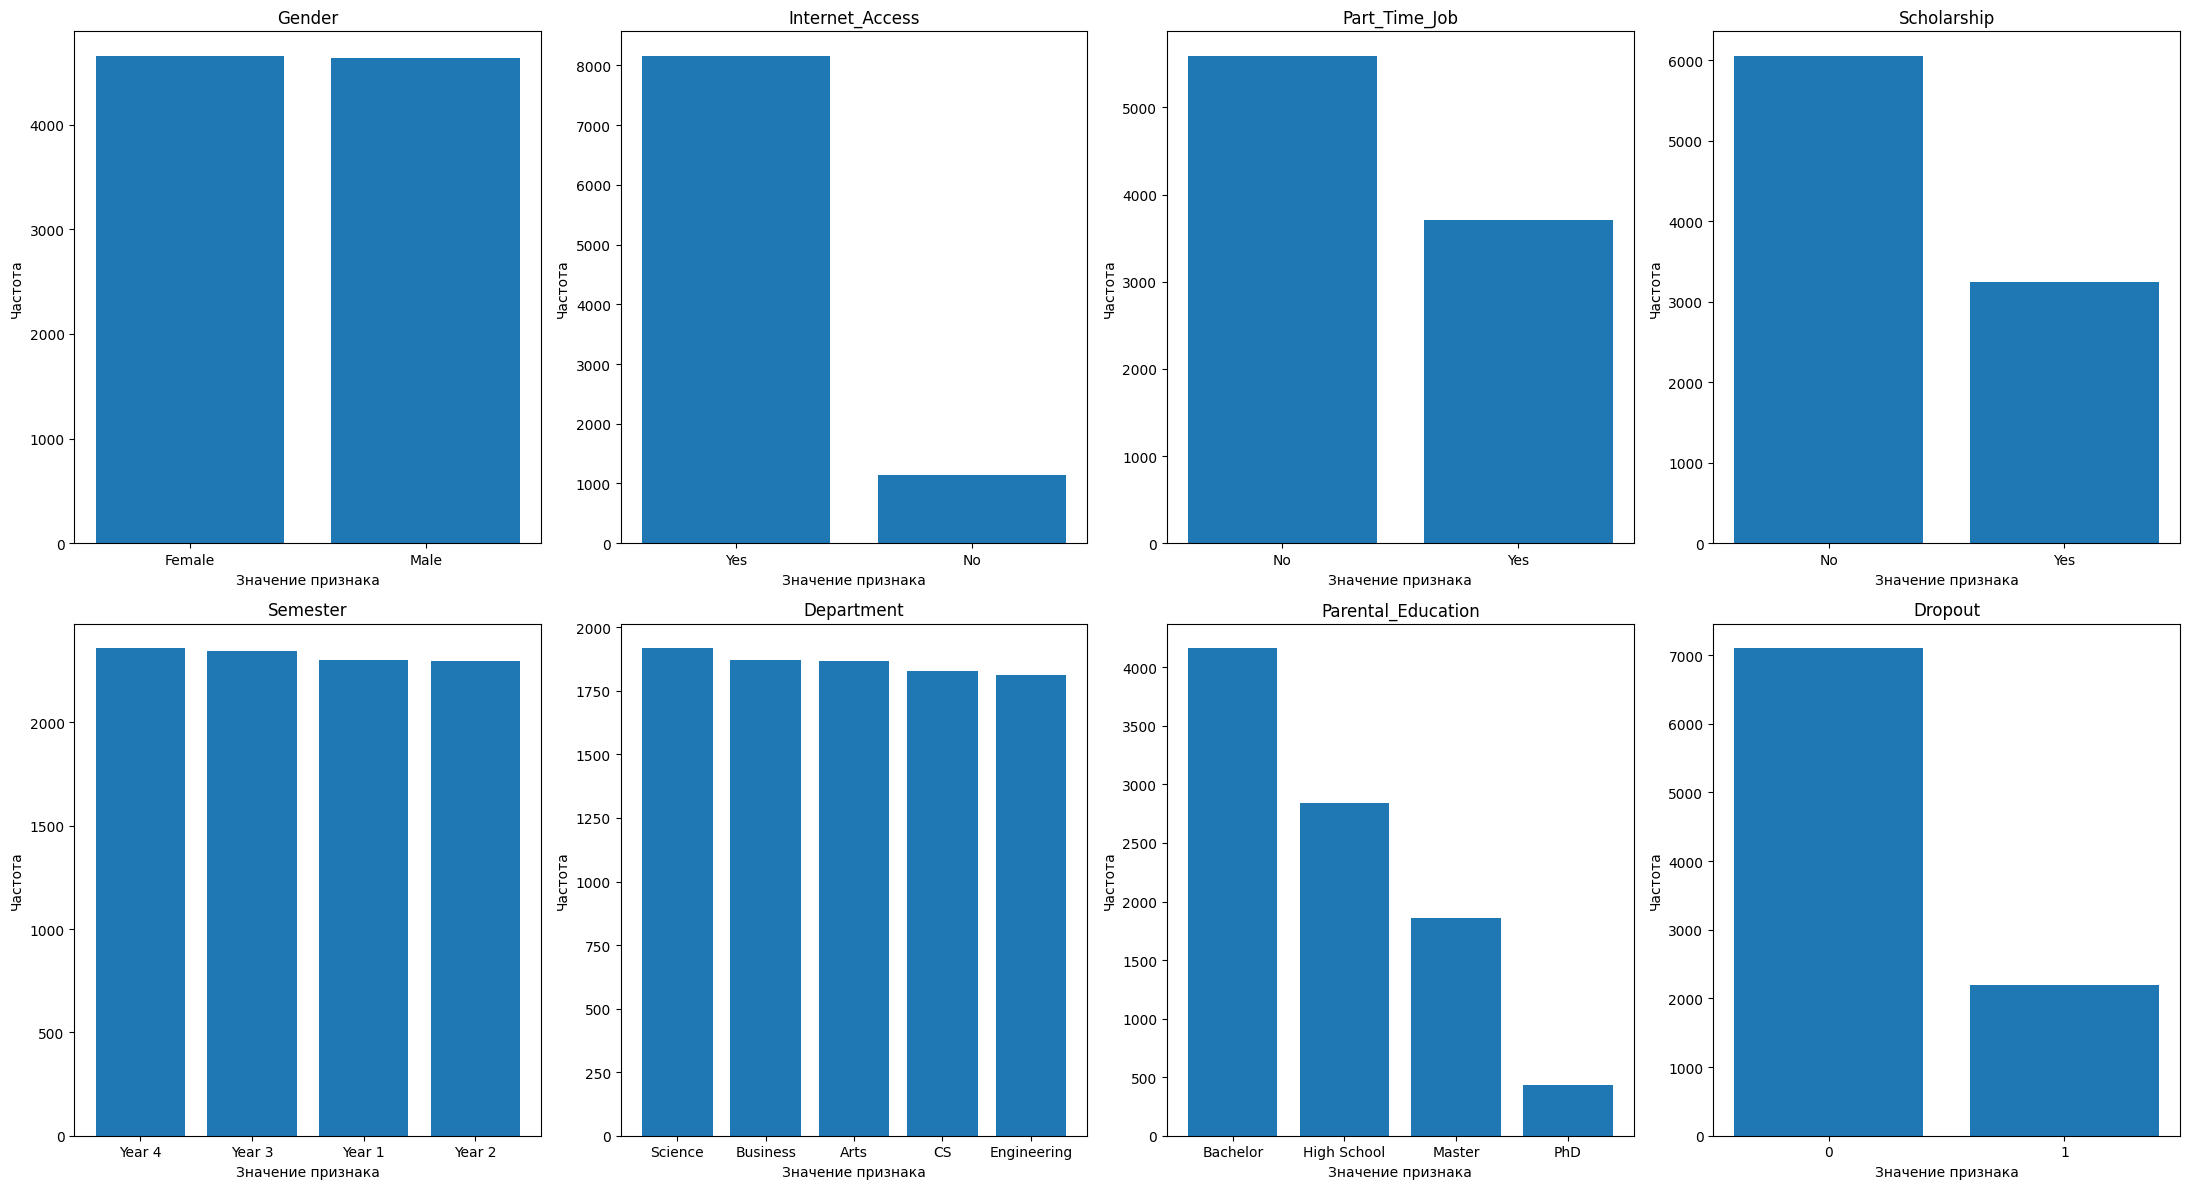

In [ ]:
categorial_columns = list(df_final.select_dtypes(['object', 'category']).columns)
categorial_columns +=['Dropout']

fig, axes = plt.subplots(2, 4, figsize=(22, 12))
axes = axes.flatten()
for i, column in enumerate(categorial_columns):
    counts = df_final[column].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(column)
    axes[i].set_xlabel('Значение признака')
    axes[i].set_ylabel('Частота')

plt.tight_layout()


### Выводы по распределениям:

- **Gender:** количество студентов мужского и женского пола примерно одинаковое, дисбаланса классоа по полу не наблюдается.
- **Internet_Access:** подавляющее большинство студентов имеет доступ к интернету. Студентов без доступа значительно меньше.
- **Part_Time_Job:** студентов без подработки больше, чем совмещающих обучение с работой.
- **Scholarship:** большинство студентов не получает стипендию.
- **Semester:** студенты распределены между четырьмя годами обучения относительно равномерно, без значительного преобладания какого-либо года.
- **Department:** количество студентов по направлениям обучения также приблизительно одинаковое. Наиболее представлено направление Science.
- **Parental_Education:** наиболее распространённым уровнем образования родителей является Bachelor, затем следует High School.

- **Dropout:** примерно 76,37% студентов не были отчислены, тогда как 23,63% были отчислены. Следовательно, целевая переменная имеет мягкий  дисбаланс классов.


### **5.3. Скрипичные графики: связь количественных признаков с отчислением**


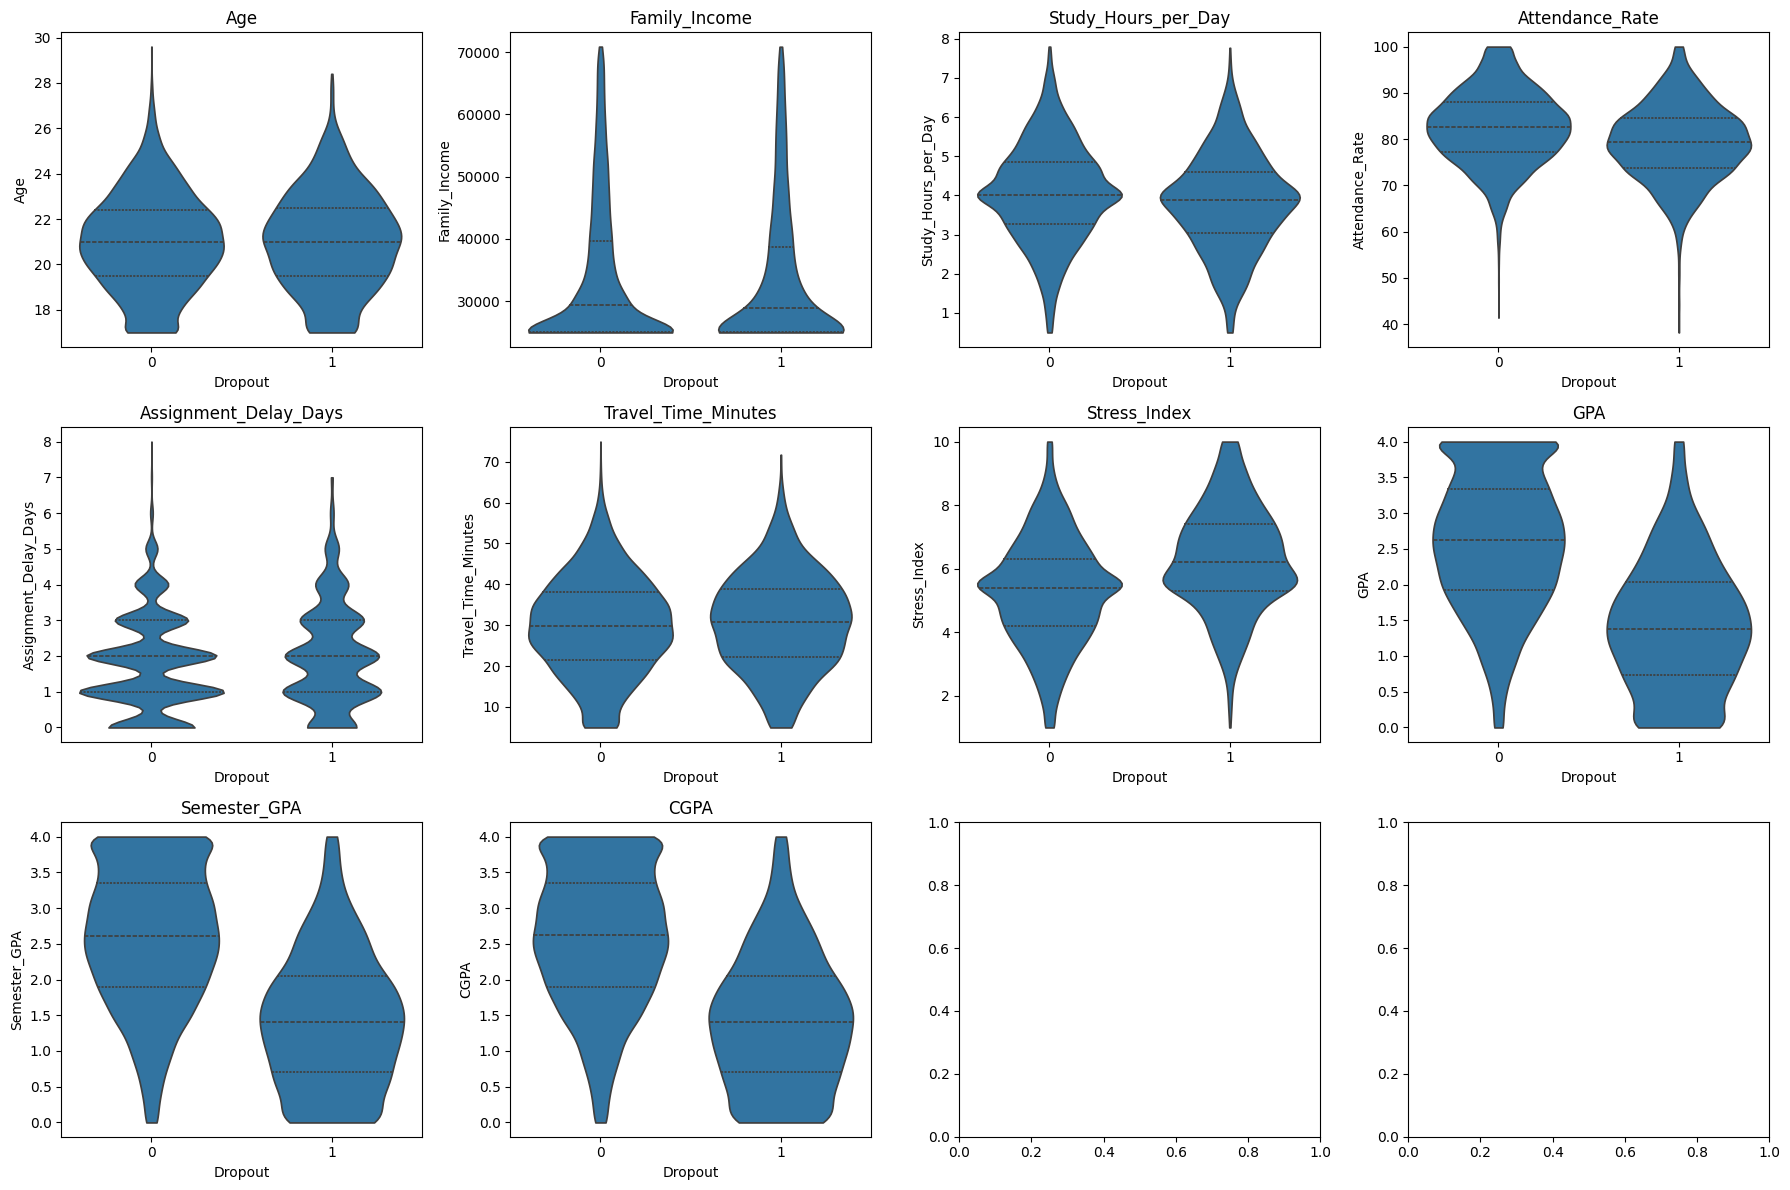

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, column in enumerate(numeric_columns):
    sns.violinplot(
        data=df_final,
        x='Dropout',
        y=column,
        ax=axes[i],
        inner='quartile',
        cut=0
    )
    axes[i].set_title(column)
    axes[i].set_xlabel('Dropout')

plt.tight_layout()
plt.show()


Скрипичные графики позволяют сравнить распределения количественных характеристик студентов, которые не были отчислены (Dropout = 0), и студентов, которые были отчислены (Dropout = 1).

### Выводы:

- **Age:** распределения возраста в двух группах практически совпадают. Заметных различий по возрасту не наблюдается.
- **Family_Income:** распределения доходов семей также достаточно похожи. По графику нельзя выделить существенное различие между группами.
- **Study_Hours_per_Day:** распределения во многом перекрываются, хотя у неотчисленных студентов центральные значения несколько выше.
- **Attendance_Rate:** у неотчисленных студентов медианная посещаемость выше, чем у отчисленных. Это указывает на отрицательную связь посещаемости с фактом отчисления.
- **Assignment_Delay_Days:** распределения количества дней задержки сдачи заданий в двух группах достаточно близки.
- **Travel_Time_Minutes:** распределения времени на дорогу похожи, существенного визуального различия между группами не наблюдается.
- **Stress_Index:** отчисленные студенты имеют более высокий медианный уровень стресса. На графике наблюдается смещение распределения вправо для группы Dropout = 1.
- **GPA, Semester_GPA и CGPA**: по всем трём показателям академической успеваемости наблюдается схожая закономерность: у неотчисленных студентов значения заметно выше, тогда как распределения отчисленных студентов смещены в сторону более низких оценок. Это указывает на отрицательную связь академической успеваемости с вероятностью отчисления.



## **6. Описательные статистики**

### **6.1 Расчет описательных статистик целевого признака**





In [ ]:
stats_dropout = df_final['Dropout'].astype('category').describe().to_frame()
stats_dropout.loc['Доля 0', 'Dropout'] = (df_final['Dropout'] == 0).mean()
stats_dropout.loc['Доля 1', 'Dropout'] = (df_final['Dropout'] == 1).mean()
stats_dropout

,Dropout
count,9298.000000
unique,2.000000
top,0.000000
freq,7101.000000
Доля 0,0.763713
Доля 1,0.236287




### Вывод по целевой переменной Dropout

- **Количество наблюдений:** после очистки данных в выборке осталось 9298 студентов.
- **Распределение значений:** наиболее часто встречается значение 0 — 7101 наблюдение (76,37%). Значение 1 встречается у 2197 студентов (23,63%).
- **Вывод:** в выборке наблюдается дисбаланс классов: студентов, которые не были отчислены, примерно в 3,2 раза больше, чем отчисленных. Это необходимо учитывать при оценке качества модели логистической регрессии.


### **6.2 Дескриптивная статитсика количественных признаков**




In [ ]:
df_final[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,9298.0,21.014777,2.140760,17.0,19.50,21.000000,22.50,29.6
Family_Income,9298.0,33810.968165,11540.922912,25000.0,25000.00,29309.000000,39573.00,70878.0
Study_Hours_per_Day,9298.0,4.004948,1.250072,0.5,3.21,4.014592,4.80,7.8
Attendance_Rate,9298.0,81.748838,8.247301,38.2,76.40,81.900000,87.40,100.0
Assignment_Delay_Days,9298.0,1.796730,1.339122,0.0,1.00,2.000000,3.00,8.0
Travel_Time_Minutes,9298.0,30.098462,11.929291,5.0,21.80,30.150000,38.40,74.9
Stress_Index,9298.0,5.512688,1.718966,1.0,4.40,5.507147,6.60,10.0
GPA,9298.0,2.308750,1.059594,0.0,1.56,2.340000,3.12,4.0
Semester_GPA,9298.0,2.299771,1.071907,0.0,1.52,2.350000,3.14,4.0
CGPA,9298.0,2.298775,1.069963,0.0,1.53,2.350000,3.14,4.0


### Вывод по количественным признакам

- **Age, Study_Hours_per_Day, Attendance_Rate, Travel_Time_Minutes и Stress_Index:** для данных признаков значения среднего и медианы практически совпадают, что указывает на приблизительную симметричность их распределений. Средний возраст студентов составляет 21 год, время учёбы — 4 часа в день, посещаемость — около 82%, время на дорогу — 30 минут, а индекс стресса — 5,51.

- **Family_Income:** средний семейный доход составляет 33 810,97, а медианный — 29 309. Превышение среднего над медианой свидетельствует о правосторонней асимметрии распределения доходов.

- **Assignment_Delay_Days:** средняя задержка сдачи заданий составляет 1,80 дня, медианная — 2 дня. Таким образом, типичная задержка составляет около двух дней.

- **GPA, Semester_GPA и CGPA:** средние значения всех трёх показателей академической успеваемости близки к 2,3 балла из 4, а медианные — около 2,35. Это указывает на близость их центральных значений, при этом заметный разброс свидетельствует о неоднородности академической успеваемости студентов.



### **6.3 Дескриптивная статитсика категориальных признаков**

In [ ]:
df_final[categorial_columns[:-1]].astype('object').describe().T

,count,unique,top,freq
Gender,9298,2,Female,4660
Internet_Access,9298,2,Yes,8161
Part_Time_Job,9298,2,No,5593
Scholarship,9298,2,No,6054
Semester,9298,4,Year 4,2359
Department,9298,5,Science,1918
Parental_Education,9298,4,Bachelor,4163


### Вывод по категориальным признакам

- **Gender:** наиболее распространённая категория — Female 4660 студентов. Следовательно, распределение студентов по полу практически равномерное.
- **Internet_Access:** доступ к интернету имеется у 8161 студента. Таким образом, подавляющее большинство студентов располагает доступом к интернету.
- **Part_Time_Job:** наиболее распространённая категория — No -  5593 студента. Большинство студентов не совмещает обучение с подработкой.
- **Scholarship:** стипендию не получают 6054 студента. Следовательно, отсутствие стипендии характерно для большей части выборки.
- **Semester:** наиболее распространённая категория — Year 4 - 2359 студентов. Ни один год обучения не имеет выраженного преобладания.
- **Department:** наиболее часто встречается направление Science - 1918 студентов. Представленность направлений обучения достаточно близка.
- **Parental_Education:** наиболее распространённый уровень образования родителей — Bachelor - 4163 студента.Таким образом, почти у половины студентов образование родителей соответствует уровню бакалавриата.

## **7. Перекодирование данных**

### **7.1 One-Hot кодирование бинарных признаков**

In [ ]:
binary_columns = ['Gender', 'Internet_Access', 'Part_Time_Job', 'Scholarship']
df_encoded = pd.get_dummies(df_final, columns=binary_columns, dtype=int, drop_first=True)
df_encoded.head()

,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout,Gender_Male,Internet_Access_Yes,Part_Time_Job_Yes,Scholarship_Yes
0,1,22.1,25000.0,3.360000,86.1,2,20.4,5.500000,0.96,0.90,0.90,Year 1,Arts,High School,0,1,1,1,0
1,2,20.7,25000.0,4.300000,68.0,2,44.0,6.800000,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1,1,1,0,0
2,3,22.4,40183.0,4.400000,70.9,0,48.9,5.500000,1.68,1.32,1.32,Year 1,Arts,Master,0,1,1,1,0
3,4,24.4,29740.5,4.014592,82.2,2,38.6,5.507147,1.78,1.77,1.77,Year 1,CS,High School,1,1,1,0,0
4,5,20.5,25319.0,4.190000,75.7,1,23.0,7.000000,1.48,0.91,0.87,Year 4,Business,Bachelor,0,0,1,0,0


### **7.2 Использоване LabelEncoder для кодирования Semester**




In [ ]:
le = LabelEncoder()
df_encoded['Semester'] = le.fit_transform(df_encoded['Semester'])
df_encoded.head()

,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout,Gender_Male,Internet_Access_Yes,Part_Time_Job_Yes,Scholarship_Yes
0,1,22.1,25000.0,3.360000,86.1,2,20.4,5.500000,0.96,0.90,0.90,0,Arts,High School,0,1,1,1,0
1,2,20.7,25000.0,4.300000,68.0,2,44.0,6.800000,1.28,1.20,1.19,2,Engineering,Bachelor,1,1,1,0,0
2,3,22.4,40183.0,4.400000,70.9,0,48.9,5.500000,1.68,1.32,1.32,0,Arts,Master,0,1,1,1,0
3,4,24.4,29740.5,4.014592,82.2,2,38.6,5.507147,1.78,1.77,1.77,0,CS,High School,1,1,1,0,0
4,5,20.5,25319.0,4.190000,75.7,1,23.0,7.000000,1.48,0.91,0.87,3,Business,Bachelor,0,0,1,0,0


### **7.3 Использование OrdinalEncoder для кодирования признака Parental_Education**

In [ ]:
encoder = OrdinalEncoder(categories=[['High School', 'Bachelor', 'Master', 'PhD']])
df_encoded['Parental_Education'] = encoder.fit_transform(
    df_final[['Parental_Education']]
).astype(int)
df_encoded.head()

,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout,Gender_Male,Internet_Access_Yes,Part_Time_Job_Yes,Scholarship_Yes
0,1,22.1,25000.0,3.360000,86.1,2,20.4,5.500000,0.96,0.90,0.90,0,Arts,0,0,1,1,1,0
1,2,20.7,25000.0,4.300000,68.0,2,44.0,6.800000,1.28,1.20,1.19,2,Engineering,1,1,1,1,0,0
2,3,22.4,40183.0,4.400000,70.9,0,48.9,5.500000,1.68,1.32,1.32,0,Arts,2,0,1,1,1,0
3,4,24.4,29740.5,4.014592,82.2,2,38.6,5.507147,1.78,1.77,1.77,0,CS,0,1,1,1,0,0
4,5,20.5,25319.0,4.190000,75.7,1,23.0,7.000000,1.48,0.91,0.87,3,Business,1,0,0,1,0,0


### **7.4. Использование One-Hot кодирования для признака  Department**

In [ ]:
df_encoded = pd.get_dummies(df_encoded, columns=['Department'], dtype=int, drop_first=True)
df_encoded.head()

,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,...,Parental_Education,Dropout,Gender_Male,Internet_Access_Yes,Part_Time_Job_Yes,Scholarship_Yes,Department_Business,Department_CS,Department_Engineering,Department_Science
0,1,22.1,25000.0,3.360000,86.1,2,20.4,5.500000,0.96,0.90,...,0,0,1,1,1,0,0,0,0,0
1,2,20.7,25000.0,4.300000,68.0,2,44.0,6.800000,1.28,1.20,...,1,1,1,1,0,0,0,0,1,0
2,3,22.4,40183.0,4.400000,70.9,0,48.9,5.500000,1.68,1.32,...,2,0,1,1,1,0,0,0,0,0
3,4,24.4,29740.5,4.014592,82.2,2,38.6,5.507147,1.78,1.77,...,0,1,1,1,0,0,0,1,0,0
4,5,20.5,25319.0,4.190000,75.7,1,23.0,7.000000,1.48,0.91,...,1,0,0,1,0,0,1,0,0,0


### Вывод по перекодированию данных

Для бинарных категориальных признаков **Gender, Internet_Access, Part_Time_Job и Scholarship** применено One-Hot кодирование, в результате которого категории преобразованы в бинарные числовые столбцы.

Признак **Semester** закодирован с помощью LabelEncoder. Полученные значения от 0 до 3 соответствуют последовательным годам обучения.

Для порядкового признака **Parental_Education** использован OrdinalEncoder,в отличие от LabelEncoder он позволяетс самостоятельно задать порядок кодирования категориальных признаковб чтобы сохранить естественнный порядок образования: High School → Bachelor → Master → PhD.

Номинальный признак **Department** было рещено преобразовать с помощью One-Hot кодирования, поскольку его категории не имеют естественного порядка, а характеризуют принадлежность объекта к определнному направлению обучения , на котором учится студент.


# **Часть 2. Исследовательская часть**

## **8. Корреляционный анализ**

Корреляционный анализ проводится на очищенной и перекодированной выборке **df_encoded**. Столбец **Student_ID** является идентификатором, а не признаком, поэтому в анализе не участвует.

Для оценки связи используются **коэффициент Пирсона**, характеризующий силу и направление линейной связи между переменными.




### **8.1. Парная корреляция**

In [ ]:
target = 'Dropout'
predictor = 'Attendance_Rate'

pearson_r, pearson_p_value = stats.pearsonr(df_encoded[predictor], df_encoded[target])
df_pair_corr = pd.DataFrame({
    "Коээфициент": [pearson_r],
    "p-value":[pearson_p_value]},
    index = ['Пирсон']
)
df_pair_corr

,Коээфициент,p-value
Пирсон,-0.168404,4.120563e-60


### Вывод по парной корреляции

Для исследования связи между посещаемостью занятий (**Attendance_Rate**) и фактом отчисления студента (**Dropout**) рассчитан коэффициент корреляции Пирсона.

Коэффициент корреляции равен  -0,1684. Полученное значение свидетельствует о слабой отрицательной линейной связи между признаками. Более высокая посещаемость связана с меньшей частотой отчислений, что является логичным.

Поскольку $p-value = 4.120563e-60$ меньше уровня значимости $\alpha = 0.05$, нулевая гипотеза об отсутствии корреляции отвергается.



### **8.2. Корреляционная матрица**

In [ ]:
corrlational_matrix = df_encoded.drop(columns=['Student_ID']).corr(method='pearson')
corrlational_matrix

,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,...,Parental_Education,Dropout,Gender_Male,Internet_Access_Yes,Part_Time_Job_Yes,Scholarship_Yes,Department_Business,Department_CS,Department_Engineering,Department_Science
Age,1.000000,-0.012521,0.001176,0.010073,0.011891,-0.012011,-0.026957,-0.010838,-0.009425,-0.009919,...,-0.003073,0.008543,-0.008977,0.001258,-0.007763,0.014796,-0.005471,-0.000395,0.011372,0.001447
Family_Income,-0.012521,1.000000,-0.003171,0.010114,-0.003079,-0.000390,-0.023909,0.006756,0.011352,0.011016,...,0.006770,-0.013215,0.010393,0.012833,0.011923,0.020935,-0.016333,0.005976,-0.001046,-0.004162
Study_Hours_per_Day,0.001176,-0.003171,1.000000,-0.014346,-0.001163,0.010601,0.012956,0.204172,0.197556,0.198127,...,0.006594,-0.083859,0.006884,-0.001815,-0.017603,-0.004961,0.015781,-0.010831,-0.003187,0.008324
Attendance_Rate,0.010073,0.010114,-0.014346,1.000000,-0.006607,0.017103,-0.013129,0.208856,0.198830,0.198892,...,-0.001743,-0.168404,-0.012314,-0.004401,-0.015408,0.010238,0.001333,-0.007133,0.001879,-0.017129
Assignment_Delay_Days,0.011891,-0.003079,-0.001163,-0.006607,1.000000,-0.000483,0.008825,-0.026271,-0.019455,-0.019964,...,0.011691,0.080844,-0.016905,0.007326,0.004612,0.007483,0.000905,0.004805,0.004081,-0.009355
Travel_Time_Minutes,-0.012011,-0.000390,0.010601,0.017103,-0.000483,1.000000,0.006180,0.012578,0.009294,0.010068,...,-0.006232,0.031297,0.000489,0.006194,0.000532,0.013493,-0.010696,0.006049,0.005184,-0.003009
Stress_Index,-0.026957,-0.023909,0.012956,-0.013129,0.008825,0.006180,1.000000,-0.372500,-0.354696,-0.354588,...,0.003299,0.247692,0.004230,-0.010673,-0.008950,-0.005312,-0.007881,0.014465,0.019445,-0.023023
GPA,-0.010838,0.006756,0.204172,0.208856,-0.026271,0.012578,-0.372500,1.000000,0.963935,0.963085,...,0.020038,-0.460114,-0.007547,0.000083,-0.002212,0.012713,0.005921,-0.000701,-0.023047,0.008084
Semester_GPA,-0.009425,0.011352,0.197556,0.198830,-0.019455,0.009294,-0.354696,0.963935,1.000000,0.999216,...,0.016973,-0.445994,-0.007156,0.002199,-0.004263,0.014577,0.008477,-0.001979,-0.018467,0.005852
CGPA,-0.009919,0.011016,0.198127,0.198892,-0.019964,0.010068,-0.354588,0.963085,0.999216,1.000000,...,0.016924,-0.445369,-0.007113,0.001825,-0.004591,0.014102,0.008687,-0.001570,-0.018741,0.005833


**Теперь построим тепловую карту:**

<Axes: >

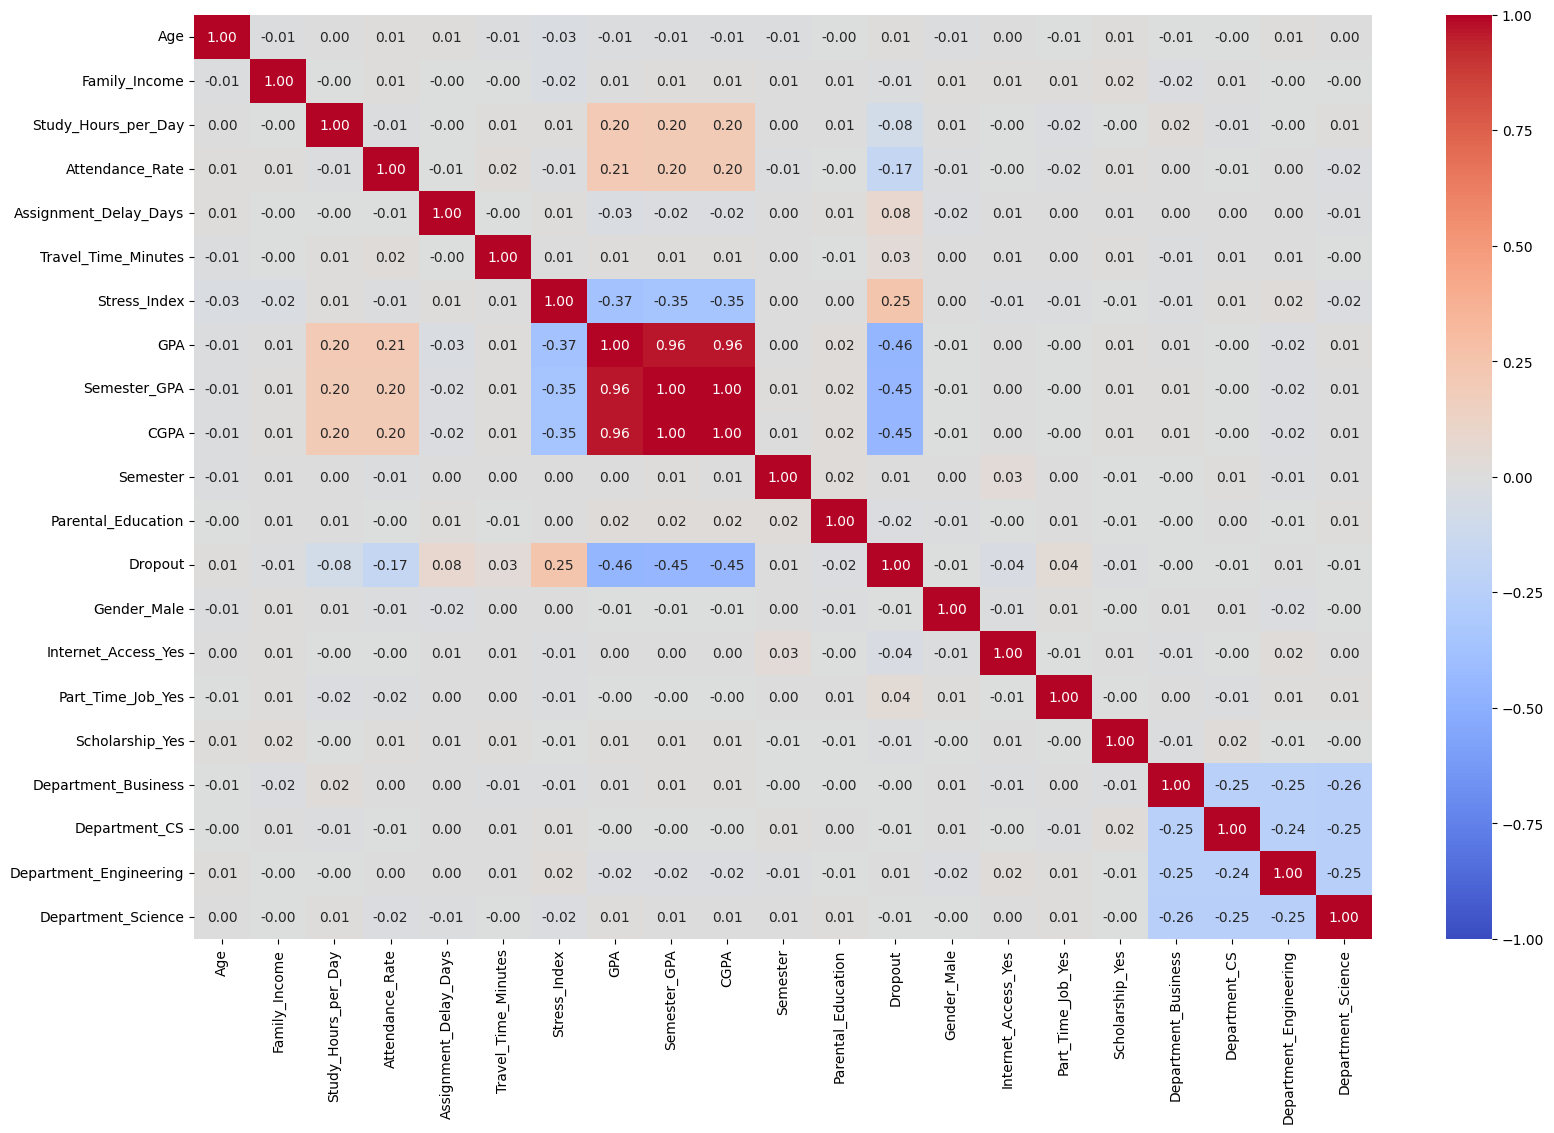

In [ ]:
plt.figure(figsize=(19, 12))
sns.heatmap(corrlational_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)

**Выведем коэффициенты корреляции с целевой переменной:**

In [ ]:
corrlational_matrix['Dropout']

,Dropout
Age,0.008543
Family_Income,-0.013215
Study_Hours_per_Day,-0.083859
Attendance_Rate,-0.168404
Assignment_Delay_Days,0.080844
Travel_Time_Minutes,0.031297
Stress_Index,0.247692
GPA,-0.460114
Semester_GPA,-0.445994
CGPA,-0.445369


### Выводы по корреляционной матрице


Корреляционная матрица Пирсона позволила нам оценить направление и силу линейных связей между признаками.

- Наиболее выраженная отрицательная корреляция с **Dropout** наблюдается у показателей академической успеваемости: **GPA** (-0,4601), **Semester_GPA** (-0,4460) и **CGPA** (-0,4454). Это означает, что более высокая академическая успеваемость связана с меньшей частотой отчислений.
- Признак **Stress_Index** имеет положительную корреляцию с отчислением (0,2477). Таким образом, более высокий уровень стресса связан с большей частотой отчислений.
- Посещаемость занятий (**Attendance_Rate**) имеет слабую отрицательную корреляцию с **Dropout** (-0,1684). Для большинства остальных признаков коэффициенты близки к нулю.
- Между показателями **GPA**, **Semester_GPA** и **CGPA** наблюдается очень высокая положительная корреляция — приблизительно 0,96 и выше. Это указывает на сильную мультиколлинеарность, поскольку данные признаки отражают близкие характеристики академической успеваемости студентов.
Поэтому при построении регресссии исключим из **Semester_GPA** и **CGPA**, чтобы веса модели были пригодны для корректной интепретации.

### **8.3. Топ-5 наиболее коррелирующих признаков**

In [ ]:
corrlational_matrix['Dropout'].drop('Dropout').sort_values(key=abs, ascending=False).head()

,Dropout
GPA,-0.460114
Semester_GPA,-0.445994
CGPA,-0.445369
Stress_Index,0.247692
Attendance_Rate,-0.168404


**Но если исключить зависимые линейно зависимые регрессоры, то наш топ коррелирующих признаков будет выглядеть так**

In [ ]:
df_encoded.corr(method='pearson')['Dropout'].drop(['Dropout', 'Semester_GPA', 'CGPA']).sort_values(key=abs, ascending=False).head()

,Dropout
GPA,-0.460114
Stress_Index,0.247692
Attendance_Rate,-0.168404
Study_Hours_per_Day,-0.083859
Assignment_Delay_Days,0.080844


### Вывод по пяти наиболее коррелирующим признакам

По абсолютной величине коэффициента корреляции Пирсона выделены пять признков, наиболее сильно связанных с целевой переменной Dropout. Наиболее выраженная отрицательная связь наблюдается у показателей академической успеваемости (**GPA**, **Semester_GPA**, **CGPA**). Уровень стресса (Stress_Index) имеет слабую положительную корреляцию с отчислением, а посещаемость (**Attendance_Rate**) — слабую отрицательную.

При этом между тремя показателями академической успеваемости наблюдается высокая мультиколлинеарность. Если исключить из рассмотрения Semester_GPA и CGPA, то в топ-5 также войдут **Study_Hours_per_Day** и **Assignment_Delay_Days**. Первый признак имеет очень слабую отрицательную корреляцию с отчислением (-0,0839), а второй — очень слабую положительную (0,0808). Таким образом, большее количество часов учёбы связано с меньшей частотой отчислений, а более длительные задержки сдачи заданий — с большей, хотя обе связи крайне слабы.

Для дальнейшего регрессионного анализа создадим отдельный датафрейм **df_model**, в котором рассмотрим сокращенный набор предикторов, исключив **Semester_GPA**, **CGPA**.  

In [ ]:
df_model = df_encoded.drop(columns=['Semester_GPA', 'CGPA']).copy()


## **9. Построение регрессионной модели**

Для прогнозирования вероятности отчисления студентов построим **модель бинарной логистической регрессии**. В качестве зависимой переменной используется **Dropout**, принимающая значение 1, если студент был отчислен, и 0 — в противном случае.

Логистическая регрессия позволяет оценить вероятность наступления события на основе характеристик студента. Модель связывает предикторы с **логарифмом отношения шансов** отчисления посредством линейной функции:

$$
\ln\left(\frac{p_i}{1-p_i}\right)=\beta_0+\sum_{j=1}^{k}\beta_jX_{ij}
$$

где:

- $p_i=P(Dropout_i=1\mid X_i)$ — вероятность отчисления $i$-го студента при заданных характеристиках;
- $\beta_0$ — свободный член модели;
- $\beta_j$ — коэффициент при $j$-м предикторе;
- $X_{ij}$ — значение $j$-го предиктора для $i$-го студента;
- $k$ — количество предикторов.

Для получения вероятности отчисления применяется логистическая функция:

$$
p_i=\frac{1}{1+e^{-\left(\beta_0+\sum_{j=1}^{k}\beta_jX_{ij}\right)}}
$$

Таким образом, предсказанная вероятность всегда находится в интервале от 0 до 1.

**Интерпретация коэффициентов:** при прочих равных условиях положительный коэффициент $\beta_j$ означает увеличение логарифма шансов отчисления при росте соответствующего признака, отрицательный — уменьшение. Величина $e^{\beta_j}$ показывает, во сколько раз изменяются шансы отчисления при увеличении предиктора на единицу.

Для построения модели используем **18 предикторов** из подготовленного датафрейма **df_model**. Обучение и оценку качества модели проведём на разных частях выборки, чтобы проверить её способность прогнозировать отчисление студентов на новых данных.

### **9.1. Выбор предикторов и разделение выборки**

Сформируем матрицу признаков **X** и целевую переменную **y**. Из набора предикторов исключим **Student_ID**, поскольку данный столбец является идентификатором студента, и **Dropout**, поскольку это целевая переменная.

Далее разделим данные на тренировочную и тестовую выборки в соотношении 80% и 20%. Тренировочная выборка будет использоваться для оценки коэффициентов модели, а тестовая — для проверки качества прогнозирования.

Для воспроизводимости разбиения установим **random_state = 42**. Параметр **stratify = y** позволит сохранить приблизительно одинаковые доли отчисленных и неотчисленных студентов в обеих выборках.


In [ ]:
predictors = df_model.columns.drop(['Student_ID', 'Dropout'])
predictors

X = df_model[predictors]
y =df_model['Dropout']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Количество элементов в тренировочной выборке: {X_train.shape[0]}')
print(f'Количество элементов в тестовой выборке: {X_test.shape[0]}')
print(f'Доля отчисленных в тренировочной выборке: {y_train.mean(): .2f}')
print(f'Доля отчисленных в тестовой выборке: {y_test.mean(): .2f}')


Количество элементов в тренировочной выборке: 7438
Количество элементов в тестовой выборке: 1860
Доля отчисленных в тренировочной выборке:  0.24
Доля отчисленных в тестовой выборке:  0.24



**Результат разделения:**

- Тренировочная выборка — 7438 наблюдений.
- Тестовая выборка — 1860 наблюдений.
- Доля отчисленных студентов в обеих выборках составляет приблизительно 24%.

Таким образом, разбиение сохранило исходное соотношение классов целевой переменной.

### **9.2. Стандартизация количественных признаков**

Перед обучением модели проведём стандартизацию количественных признаков с помощью **StandardScaler**. Это позволит привести признаки, измеряемые в разных единицах, к сопоставимому масштабу.

Стандартизация выполняется по формуле:

$$
z_i=\frac{x_i-\mu}{\sigma},
$$

где $\mu$ — среднее значение признака, а $\sigma$ — его стандартное отклонение, рассчитанные на тренировочной выборке.

Стандартизируем восемь количественных признаков: **Age**, **Family_Income**, **Study_Hours_per_Day**, **Attendance_Rate**, **Assignment_Delay_Days**, **Travel_Time_Minutes**, **Stress_Index** и **GPA**.

Бинарные признаки оставим без изменений, чтобы сохранить их интерпретацию при переходе между категориями 0 и 1. Порядковые признаки **Semester** и **Parental_Education** также оставим в исходной кодировке.



In [ ]:
columns_for_standart_scaler = [
    'Age', 'Family_Income', 'Study_Hours_per_Day',
    'Attendance_Rate', 'Assignment_Delay_Days',
    'Travel_Time_Minutes', 'Stress_Index', 'GPA'
]

In [ ]:
scaler = StandardScaler()


X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[columns_for_standart_scaler] = scaler.fit_transform(X_train_scaled[columns_for_standart_scaler])
X_test_scaled[columns_for_standart_scaler] = scaler.transform(X_test_scaled[columns_for_standart_scaler])


In [ ]:
X[columns_for_standart_scaler].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Age,9298.0,21.015,2.141,17.0,19.50,21.000,22.50,29.6
Family_Income,9298.0,33810.968,11540.923,25000.0,25000.00,29309.000,39573.00,70878.0
Study_Hours_per_Day,9298.0,4.005,1.250,0.5,3.21,4.015,4.80,7.8
Attendance_Rate,9298.0,81.749,8.247,38.2,76.40,81.900,87.40,100.0
Assignment_Delay_Days,9298.0,1.797,1.339,0.0,1.00,2.000,3.00,8.0
Travel_Time_Minutes,9298.0,30.098,11.929,5.0,21.80,30.150,38.40,74.9
Stress_Index,9298.0,5.513,1.719,1.0,4.40,5.507,6.60,10.0
GPA,9298.0,2.309,1.060,0.0,1.56,2.340,3.12,4.0


In [ ]:
scaled_columns_info = X_train_scaled[columns_for_standart_scaler].describe().T.round(3)

scaled_columns_info

,count,mean,std,min,25%,50%,75%,max
Age,7438.0,-0.0,1.0,-1.879,-0.707,-0.004,0.699,3.980
Family_Income,7438.0,0.0,1.0,-0.763,-0.763,-0.387,0.496,3.201
Study_Hours_per_Day,7438.0,-0.0,1.0,-2.793,-0.637,0.014,0.641,3.013
Attendance_Rate,7438.0,-0.0,1.0,-5.289,-0.662,0.018,0.686,2.216
Assignment_Delay_Days,7438.0,-0.0,1.0,-1.347,-0.599,0.149,0.898,3.890
Travel_Time_Minutes,7438.0,0.0,1.0,-2.107,-0.702,0.005,0.695,3.774
Stress_Index,7438.0,-0.0,1.0,-2.633,-0.650,-0.004,0.634,2.617
GPA,7438.0,-0.0,1.0,-2.179,-0.706,0.041,0.758,1.599


### Вывод по стандартизации

После преобразования средние значения стандартизированных признаков на тренировочной выборке практически равны нулю, а стандартные отклонения — единице. Таким образом, количественные признаки приведены к единому масштабу.

При дальнейшей интерпретации коэффициентов логистической регрессии будем учитывать, что увеличение стандартизированного признака на единицу соответствует увеличению исходного признака на одно стандартное отклонение тренировочной выборки.

### **9.3. Обучение модели логистической регрессии**

Обучим модель логистической регрессии на тренировочной выборке.

Для оценки коэффициентов используем модель без регуляризации. В таком случае коэффициенты оцениваются методом максимального правдоподобия, который позволяет подобрать параметры, максимизирующие вероятность наблюдения фактических значений целевой переменной при заданных характеристиках студентов.

В результате обучения получим оценки свободного члена $\hat\beta_0$ и коэффициентов $\hat\beta_1,\ldots,\hat\beta_{18}$.

Далее рассмотрим полученное уравнение регрессии, ее коэффициенты и их содержательную интерпретацию.

In [ ]:
logreg_model = LogisticRegression(penalty=None)
model = logreg_model.fit(X_train_scaled, y_train)


In [ ]:
model_coef = pd.DataFrame({'Коэффиенты модели w_i' : model.coef_[0],
                           'Отношение шансов exp(w_i)' : np.exp(model.coef_[0])
                           }, index=model.feature_names_in_)
model_coef.loc['Cвободный член модели'] = [model.intercept_[0], np.exp(model.intercept_[0])]
model_coef

,Коэффиенты модели w_i,Отношение шансов exp(w_i)
Age,0.001798,1.001800
Family_Income,-0.035142,0.965468
Study_Hours_per_Day,-0.021299,0.978926
Attendance_Rate,-0.271537,0.762207
Assignment_Delay_Days,0.200913,1.222518
Travel_Time_Minutes,0.113817,1.120547
Stress_Index,0.321682,1.379445
GPA,-1.200602,0.301013
Semester,0.010845,1.010904
Parental_Education,-0.041610,0.959243


### **9.4. Оцененное уравнение логистической регрессии и интерпретация его коэффициентов**

Полученную модель представим двумя эквивалентными способами.

#### **1. Через логарифм отношения шансов:**

$$
\ln\left(\frac{p_i}{1-p_i}\right)=z_i
$$

где

$$
\begin{aligned}
z_i ={}& -1.2788
+0.0018\,Age_i
-0.0351\,FamilyIncome_i\\
&-0.0213\,StudyHours_i
-0.2715\,Attendance_i
+0.2009\,AssignmentDelay_i\\
&+0.1138\,TravelTime_i
+0.3217\,StressIndex_i
-1.2006\,GPA_i\\
&+0.0108\,Semester_i
-0.0416\,ParentalEducation_i
-0.0870\,GenderMale_i\\
&-0.3530\,InternetAccessYes_i
+0.2178\,PartTimeJobYes_i
-0.0037\,ScholarshipYes_i\\
&-0.0641\,DepartmentBusiness_i
-0.1087\,DepartmentCS_i\\
&-0.0537\,DepartmentEngineering_i
-0.0917\,DepartmentScience_i.
\end{aligned}
$$

#### **2. Через вероятность отчисления:**

$$
p_i=\frac{1}{1+\exp(-z_i)}
$$

Здесь $p_i$ — прогнозируемая вероятность отчисления студента, а $z_i$ — линейная комбинация признаков с оценёнными коэффициентами. Количественные признаки представлены в стандартизированном виде, остальные — в ранее заданной кодировке. Названия переменных сокращены для компактности записи.



Для интерпретации коэффициентов модели рассчитаем **отношение шансов (Odds Ratio)**:

$$
OR_j=e^{\hat\beta_j}.
$$

При $OR_j>1$ шансы отчисления возрастают, при $OR_j<1$ — снижаются. Все интерпретации выполняются **при прочих равных условиях**.






#### **Интерпретация модели:**



#### **1. Количественные признаки**

Все количественные признаки были стандартизированы. Поэтому приведённые ниже изменения шансов отчисления соответствуют **увеличению каждого показателя на одно стандартное отклонение при прочих равных условиях**.

- **Age:** увеличение возраста связано с повышением шансов отчисления на **0,18%**. Оценённая связь практически отсутствует.
- **Family_Income:** увеличение дохода семьи связано со снижением шансов отчисления на **3,45%**.
- **Study_Hours_per_Day:** увеличение продолжительности самостоятельной учёбы связано со снижением шансов отчисления на **2,11%**.
- **Attendance_Rate:** повышение посещаемости занятий связано со снижением шансов отчисления на **23,78%**.
- **Assignment_Delay_Days:** увеличение задержки сдачи заданий связано с повышением шансов отчисления на **22,25%**.
- **Travel_Time_Minutes:** увеличение времени на дорогу до университета связано с повышением шансов отчисления на **12,05%**.
- **Stress_Index:** повышение уровня стресса связано с увеличением шансов отчисления на **37,94%**.
- **GPA:** повышение академической успеваемости связано со снижением шансов отчисления на **69,90%**.

#### **2. Порядковые признаки**

- **Semester:** увеличение закодированного значения семестра на единицу связано с повышением шансов отчисления на **1,09%**.
- **Parental_Education:** повышение уровня образования родителей на одну категорию связано со снижением шансов отчисления на **4,08%**.

#### **3. Бинарные признаки**

Для бинарных признаков интерпретируем изменение шансов при переходе от категории 0 к категории 1.

- **Gender_Male:** у студентов мужского пола шансы отчисления ниже на **8,33%** по сравнению со студентами женского пола.
- **Internet_Access_Yes:** у студентов с доступом к интернету шансы отчисления ниже на **29,74%** по сравнению со студентами без доступа.
- **Part_Time_Job_Yes:** наличие подработки связано с повышением шансов отчисления на **24,33%**.
- **Scholarship_Yes:** наличие стипендии связано со снижением шансов отчисления на **0,37%**. Оценённая связь практически отсутствует.

#### **4. Направление обучения**

Базовой категорией для сравнения выступает **Arts**.

- **Department_Business:** шансы отчисления ниже на **6,20%** по сравнению с направлением Arts.
- **Department_CS:** шансы отчисления ниже на **10,30%** по сравнению с Arts.
- **Department_Engineering:** шансы отчисления ниже на **5,23%** по сравнению с Arts.
- **Department_Science:** шансы отчисления ниже на **8,76%** по сравнению с Arts.

### Выводы:
 Наиболее выраженные связи с шансами отчисления наблюдаются у **GPA**, **Stress_Index** и **Attendance_Rate**. Более высокая академическая успеваемость и посещаемость связаны со снижением шансов отчисления, тогда как повышенный уровень стресса — с их увеличением.

### **9.5. Прогнозирование вероятности отчисления**

На тестовой выборке получим вероятности отчисления с помощью **predict_proba()** и предсказанные классы с помощью **predict()**.

При стандартном пороге 0,5 студент относится к классу 1, если прогнозируемая вероятность отчисления не меньше 50%. Сравним первые предсказания с фактическими значениями целевой переменной.

In [ ]:
y_predict_probability = model.predict_proba(X_test_scaled)
y_predict_class = model.predict(X_test_scaled)

pd.DataFrame({
    'P(студент не отчислен)': y_predict_probability[:, 0],
    'P(студент отчислен)': y_predict_probability[:, 1],
    'Педсказанный класс': y_predict_class,
    'Фактический класс': y_test.values
}).head().round(3)

,P(студент не отчислен),P(студент отчислен),Педсказанный класс,Фактический класс
0,0.427,0.573,1,0
1,0.978,0.022,0,0
2,0.935,0.065,0,0
3,0.312,0.688,1,1
4,0.989,0.011,0,0


### **9.6. Оценка качества модели**

Для оценки качества классификации рассчитаем **Accuracy, Precision, Recall, F1-score, ROC-AUC и Log Loss**.



In [ ]:
model_metrics = pd.DataFrame({
    'Значение': [accuracy_score(y_test, y_predict_class),
                 precision_score(y_test, y_predict_class),
                 recall_score(y_test, y_predict_class),
                 f1_score(y_test, y_predict_class),
                 roc_auc_score(y_test, y_predict_probability[:, 1]),
                 log_loss(y_test, y_predict_probability[:, 1])
                 ]
}, index=['Accuracy',
          'Precision',
          'Recall',
          'F1_score',
          'ROC_AUC',
          'Log_loss'
          ])
model_metrics.round(4)

,Значение
Accuracy,0.8016
Precision,0.6316
Recall,0.3827
F1_score,0.4766
ROC_AUC,0.8165
Log_loss,0.4234



### Вывод по метрикам качества

По результатам оценки модели получены следующие значения:

- **Accuracy = 0,8016:** модель правильно классифицирует около 80,16% студентов тестовой выборки.
- **Precision = 0,6316:** среди студентов, которым модель предсказала отчисление, действительно отчислены около 63,16%.
- **Recall = 0,3827:** модель обнаруживает только 38,27% всех реально отчисленных студентов.
- **F1-score = 0,4766:** сравнительно невысокое значение связано прежде всего с низкой полнотой обнаружения отчисленных студентов.
- **ROC-AUC = 0,8165:** модель достаточно хорошо различает студентов по степени риска отчисления.
- **Log Loss = 0,4234:** характеризует ошибку вероятностных прогнозов. Для оценки данного значения далее сравним его с результатом наивной модели.

Таким образом, логистическая регрессия демонстрирует сравнительно высокую общую точность и хорошую способность ранжировать студентов по риску отчисления. Однако при стандартном пороге классификации 0,5 модель пропускает значительную часть действительно отчисленных студентов.


### **9.7. Построение ROC-кривой**

Для более подробной оценки способности модели различать классы построим ROC-кривую.

Она отражает зависимость **True Positive Rate (TPR)** от **False Positive Rate (FPR)** при различных порогах классификации:

$$
TPR=\frac{TP}{TP+FN},
$$

$$
FPR=\frac{FP}{FP+TN}.
$$

В качестве ориентира также построим диагональную линию случайного классификатора, для которого **ROC-AUC = 0,5**.


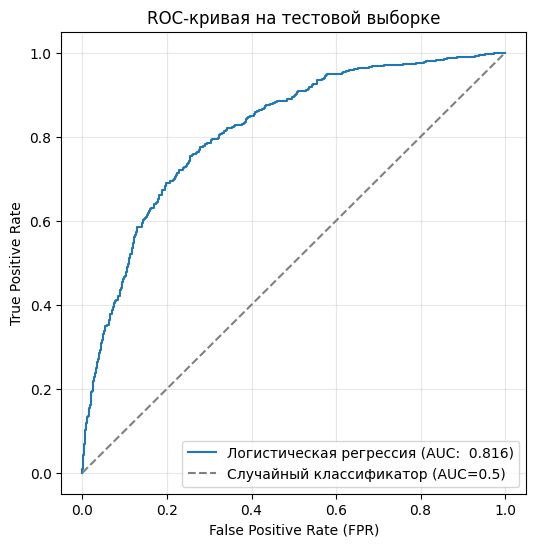

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_predict_probability[:, 1])
model_roc_auc = roc_auc_score(y_test, y_predict_probability[:, 1])

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'Логистическая регрессия (AUC: {model_roc_auc: .3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label=f'Случайный классификатор (AUC=0.5) ')
plt.title('ROC-кривая на тестовой выборке')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


### Вывод по ROC-кривой

Построенная ROC-кривая располагается преимущественно выше линии случайного классификатора. Значение **ROC-AUC = 0,8165** свидетельствует о достаточно хорошей способности модели различать студентов по вероятности отчисления.

Это означает, что примерно в 81,65% случайных пар, состоящих из отчисленного и неотчисленного студентов, модель присваивает более высокий риск действительно отчисленному студенту, с учётом возможных совпадений оценок.



### **9.8. Построение матрицы ошибок**

Для анализа ошибок классификации построим матрицу ошибок (**Confusion Matrix**), которая позволяет сравнить предсказанные классы с фактическими значениями целевой переменной.





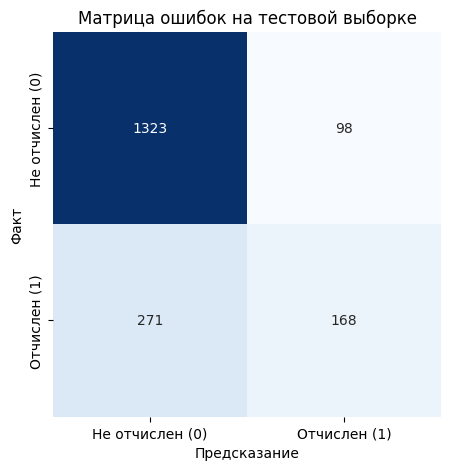

TN=1323, FP=98, FN=271, TP=168


In [ ]:
conf_matrix = confusion_matrix(y_test, y_predict_class)
plt.figure(figsize=(5, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Не отчислен (0)', 'Отчислен (1)'],
            yticklabels=['Не отчислен (0)', 'Отчислен (1)'])
plt.title('Матрица ошибок на тестовой выборке')
plt.xlabel('Предсказание')
plt.ylabel('Факт')
plt.show()

TN, FP, FN, TP = conf_matrix.ravel()
print(f'TN={TN}, FP={FP}, FN={FN}, TP={TP}')


### Вывод по матрице ошибок

На тестовой выборке получены следующие результаты:

- **TN = 1323:** модель правильно определила студентов, которые не были отчислены.
- **TP = 168:** модель правильно обнаружила 168 действительно отчисленных студентов.
- **FP = 98:** модель ошибочно предсказала отчисление 98 студентам, которые не были отчислены.
- **FN = 271:** модель не смогла обнаружить 271 действительно отчисленного студента.

Наиболее заметная проблема модели заключается в большом количестве ложноотрицательных прогнозов (**FN**). Из 439 действительно отчисленных студентов модель правильно обнаружила только 168.

Следовательно, несмотря на сравнительно высокую **Accuracy**, модель имеет ограниченную полноту обнаружения студентов с риском отчисления при выбранном пороге 0,5.

### **9.9. Сравнение логистической регрессии с наивной моделью**

Для оценки качества вероятностных прогнозов сравним построенную логистическую регрессию с наивной моделью.

Наивная модель не использует характеристики студентов, а каждому наблюдению присваивает одинаковую вероятность отчисления, равную доле отчисленных студентов в тренировочной выборке.

В качестве метрики сравнения используем **Log_Loss**, рассчитываемую по формуле:

$$
Log_Loss=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\ln(\hat p_i)+(1-y_i)\ln(1-\hat p_i)\right],
$$

где $y_i$ — фактический класс студента, а $\hat p_i$ — предсказанная вероятность отчисления.

Чем меньше значение **Log_Loss**, тем лучше предсказанные вероятности согласуются с фактическими исходами.



In [ ]:
model_log_loss = log_loss(y_test, y_predict_probability)

naive_predict_probability = np.full(len(y_test), y_train.mean())

naive_log_loss = log_loss(y_test, naive_predict_probability)

print(f'Log-loss для построенной модели: {model_log_loss:.3f}')
print(f'Log-loss для наивной модели: {naive_log_loss: .3f}')

Log-loss для построенной модели: 0.423
Log-loss для наивной модели:  0.546


### Вывод по сравнению моделей

Для логистической регрессии получено значение **Log Loss = 0,423**, тогда как для наивной модели — **0,546**.

Следовательно, логистическая регрессия обеспечивает меньшую ошибку вероятностного прогнозирования по сравнению с моделью, использующей только среднюю долю отчисленных студентов.

Это подтверждает, что учёт индивидуальных характеристик студентов позволяет улучшить прогнозирование вероятности отчисления по сравнению с простым базовым подходом.


## **10. Тестирование статистических гипотез**

Все тесты проводятся на очищенной выборке **df_final** при уровне значимости $\alpha=0.05$.

| № | Тест | Признак | Функция |
|---|---|---|---|
| 10.1 | Критерий Шапиро–Уилка | 8 количественных признаков | `scipy.stats.shapiro` |
| 10.2 | Одновыборочный Z-тест | Study_Hours_per_Day | `statsmodels.stats.weightstats.ztest` |
| 10.3 | Одновыборочный t-тест | Attendance_Rate | `scipy.stats.ttest_1samp` |
| 10.4 | Парный t-тест | Semester_GPA и CGPA | `scipy.stats.ttest_rel` |
| 10.5 | Двухвыборочный t-тест Уэлча | GPA по группам Dropout | `scipy.stats.ttest_ind` |
| 10.6 | U-тест Манна–Уитни | Stress_Index по группам Dropout | `scipy.stats.mannwhitneyu` |
| 10.7 | Критерий χ² Пирсона на независимость | Part_Time_Job и Dropout | `scipy.stats.chi2_contingency` |
| 10.8 | Одновыборочный Z-тест для пропорции | Dropout | `statsmodels.stats.proportion.proportions_ztest` |


### **10.1. Проверка нормальности распределений (критерий Шапиро–Уилка)**

Проверим нормальность распределений восьми количественных признаков с помощью критерия Шапиро–Уилка.

**Гипотезы:**

- $H_0$: распределение исследуемого признака является нормальным.
- $H_1$: распределение исследуемого признака отличается от нормального.

**Статистика критерия:**

$$
W=\frac{\left(\sum_{i=1}^{n}a_i x_{(i)}\right)^2}{\sum_{i=1}^{n}(x_i-\bar{x})^2}
$$

где $x_{(i)}$ — упорядоченные значения выборки, $\bar{x}$ — выборочное среднее, $a_i$ — коэффициенты, определяемые на основе порядковых статистик нормального распределения.

**Особенность применения:** поскольку наш датасет содержит 9298 наблюдений, для каждого признака случайным образом отберём 5000 наблюдений с **random_state = 42**. Это связано с тем, что в реализации **scipy.stats.shapiro()** при объёме выборки более 5000 статистика $W$ рассчитывается, но точность p-value не гарантируется.

При уровне значимости $\alpha=0.05$ отвергаем $H_0$, если **p-value < 0.05**.

In [ ]:
shapiro_features = [    'Age', 'Family_Income', 'Study_Hours_per_Day',
    'Attendance_Rate', 'Assignment_Delay_Days',
    'Travel_Time_Minutes', 'Stress_Index', 'GPA']

shapiro_rows = []

for column in shapiro_features:
  sample = df_final[column].sample(n=5000, random_state=42)
  w_stat, p_value = stats.shapiro(sample)

  shapiro_rows.append({
      'Признак':column,
      'W(наблюдаемое значение)': w_stat,
      'p_value': p_value,
      'Вывод': 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается'
  })

shapiro_results = pd.DataFrame(shapiro_rows)
shapiro_results

,Признак,W(наблюдаемое значение),p_value,Вывод
0,Age,0.990901,2.063806e-17,H0 отвергается
1,Family_Income,0.767143,1.697794e-64,H0 отвергается
2,Study_Hours_per_Day,0.997955,3.518284e-06,H0 отвергается
3,Attendance_Rate,0.994532,7.571286e-13,H0 отвергается
4,Assignment_Delay_Days,0.911705,3.870867e-47,H0 отвергается
5,Travel_Time_Minutes,0.995338,1.421622e-11,H0 отвергается
6,Stress_Index,0.995883,1.240217e-10,H0 отвергается
7,GPA,0.974097,3.407974e-29,H0 отвергается


### Вывод

Для всех восьми исследованных признаков получено **p-value < 0.05**, поэтому нулевая гипотеза о нормальности распределений отвергается. При этом для некоторых признаков статистика $W$ близка к единице, что указывает на относительно небольшие отклонения от нормальности. Большой объём подвыборки (5000 наблюдений) позволяет обнаруживать даже небольшие отклонения.


### **10.2. Одновыборочный Z-тест**

Проверим гипотезу о том, что среднее время учёбы студентов составляет 4 часа в день. Поскольку объём выборки достаточно велик, используем Z-тест с нормальным приближением, оценивая стандартное отклонение по выборочным данным.

**Гипотезы:**

- $H_0:\mu=4$
- $H_1:\mu\neq4$

**Статистика теста:**

$$
Z=\frac{\bar X-\mu_0}{s/\sqrt{n}}
$$

где $\bar X$ — выборочное среднее, $\mu_0=4$ — гипотетическое среднее, $s$ — выборочное стандартное отклонение, $n$ — объём выборки.

При справедливости $H_0$ статистика имеет приблизительно стандартное нормальное распределение. Уровень значимости: $\alpha=0.05$.


In [ ]:
from statsmodels.stats.weightstats import ztest

x = df_final['Study_Hours_per_Day']

z_stat, p_value = ztest(
    x,
    value=4,
    alternative='two-sided'
)

print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.4f}')
print('Вывод:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Z-статистика: 0.3817
p-value: 0.7027
Вывод: H0 не отвергается


### Вывод

Получено **Z = 0.3817**, **p-value = 0.7027 > 0.05**. Нулевая гипотеза не отвергается: статистически значимых отличий среднего времени учёбы от 4 часов в день не обнаружено.

### **10.3. Одновыборочный t-тест**

Проверим гипотезу о том, что средняя посещаемость занятий (**Attendance_Rate**) превышает 80%.

**Гипотезы:**

- $H_0: \mu \leq 80$
- $H_1: \mu > 80$

**Статистика теста:**

$$
t=\frac{\bar X-\mu_0}{s/\sqrt{n}}
$$

где $s$ — выборочное стандартное отклонение. При граничном значении нулевой гипотезы статистика имеет распределение Стьюдента с $n-1$ степенями свободы при выполнении классических предпосылок.

Уровень значимости: $\alpha=0.05$.

In [ ]:
x = df_final['Attendance_Rate']

t_stat, p_value = stats.ttest_1samp(x, popmean=80,
    alternative='greater')

print(f'Выборочное среднее: {x.mean():.4f}')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value:.4e}')
print('Вывод:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Выборочное среднее: 81.7488
t-статистика: 20.4471
p-value: 3.1243e-91
Вывод: H0 отвергается


### Вывод

Получено **t = 20.4471**, **p-value < 0.001**. Нулевая гипотеза отвергается. Средняя посещаемость составляет **81.75%**, что статистически значимо превышает 80%.

### **10.4. Парный t-тест**

Проверим, отличается ли средний балл за семестр (**Semester_GPA**) от накопленного среднего балла (**CGPA**) у одних и тех же студентов.

**Гипотезы:**

- $H_0:\mu_d=0$
- $H_1:\mu_d\neq0$

где $d_i=Semester\_GPA_i-CGPA_i$ — разность показателей для каждого студента.

**Статистика теста:**

$$
t=\frac{\bar d}{s_d/\sqrt{n}}
$$

где $\bar d$ — средняя разность, $s_d$ — стандартное отклонение разностей. Уровень значимости: $\alpha=0.05$.

In [ ]:
semester_gpa = df_final['Semester_GPA']
cgpa = df_final['CGPA']

t_stat, p_value = stats.ttest_rel(semester_gpa, cgpa,
    alternative='two-sided')

print(f'Средняя разность: {(semester_gpa - cgpa).mean():.5f}')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value:.4f}')
print('Вывод:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Средняя разность: 0.00100
t-статистика: 2.2615
p-value: 0.0237
Вывод: H0 отвергается


### Вывод

Получено **t = 2.2615**, **p-value = 0.0237 < 0.05**. Нулевая гипотеза отвергается: между **Semester_GPA** и **CGPA** обнаружено статистически значимое различие. Однако средняя разность составляет всего **0.001 балла**, поэтому практическая значимость различия крайне мала.

### **10.5. Двухвыборочный t-тест для независимых выборок**

Проверим гипотезу о том, что средний **GPA** неотчисленных студентов выше, чем у отчисленных.

**Гипотезы:**

- $H_0: \mu_0 \leq \mu_1$
- $H_1: \mu_0 > \mu_1$

где $\mu_0$ — средний GPA неотчисленных студентов, $\mu_1$ — средний GPA отчисленных.

**Статистика теста Уэлча:**

$$
t=\frac{\bar X_0-\bar X_1}{\sqrt{\frac{s_0^2}{n_0}+\frac{s_1^2}{n_1}}}
$$

Тест не предполагает равенства генеральных дисперсий. Учитывая большой объём обеих независимых выборок, используем приближение на основе центральной предельной теоремы.

Уровень значимости: $\alpha=0.05$.

In [ ]:
gpa_0 = df_final.loc[df_final['Dropout'] == 0, 'GPA']
gpa_1 = df_final.loc[df_final['Dropout'] == 1, 'GPA']

t_stat, p_value = stats.ttest_ind(gpa_0, gpa_1, equal_var=False,
    alternative='greater')

print(f'Средний GPA (не отчислены): {gpa_0.mean():.4f}')
print(f'Средний GPA (отчислены): {gpa_1.mean():.4f}')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value:.4e}')
print('Вывод:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Средний GPA (не отчислены): 2.5799
Средний GPA (отчислены): 1.4323
t-статистика: 50.9502
p-value: 0.0000e+00
Вывод: H0 отвергается


### Вывод

Получено **t = 50.9502**, **p-value < 0.001**. Нулевая гипотеза отвергается. Средний **GPA** неотчисленных студентов (**2.5799**) статистически значимо выше, чем у отчисленных (**1.4323**).

### **10.6. U-тест Манна–Уитни**

Проверим гипотезу о том, что уровень стресса (**Stress_Index**) у отчисленных студентов выше, чем у неотчисленных. Используем непараметрический U-тест Манна–Уитни.

**Гипотезы:**

- $H_0$: распределения уровня стресса в двух группах одинаковы.
- $H_1$: уровень стресса у отчисленных студентов имеет тенденцию быть выше.

**Статистика теста:**

$$
U_1=R_1-\frac{n_1(n_1+1)}{2}
$$

где $R_1$ — сумма рангов наблюдений первой группы, $n_1$ — количество наблюдений в ней.

Уровень значимости: $\alpha=0.05$.

In [ ]:
stress_1 = df_final.loc[df_final['Dropout'] == 1, 'Stress_Index']
stress_0 = df_final.loc[df_final['Dropout'] == 0, 'Stress_Index']

u_stat, p_value = stats.mannwhitneyu(stress_1, stress_0,
    alternative='greater')

print(f'Медиана стресса (отчислены): {stress_1.median():.4f}')
print(f'Медиана стресса (не отчислены): {stress_0.median():.4f}')
print(f'U-статистика: {u_stat:.4f}')
print(f'p-value: {p_value:.4e}')
print('Решение:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Медиана стресса (отчислены): 6.2000
Медиана стресса (не отчислены): 5.4000
U-статистика: 10375607.5000
p-value: 1.1743e-121
Решение: H0 отвергается


### Вывод

Получено **U = 10375607.5**, **p-value < 0.001**. Нулевая гипотеза отвергается: уровень стресса у отчисленных студентов имеет статистически значимую тенденцию быть выше. Медианный **Stress_Index** составляет **6.2** против **5.4** у неотчисленных.

### **10.7. Критерий χ² Пирсона для проверки независимости**

Проверим гипотезу о наличии связи между подработкой студента (**Part_Time_Job**) и фактом его отчисления (**Dropout**).

**Гипотезы:**

- $H_0$: признаки **Part_Time_Job** и **Dropout** независимы.
- $H_1$: признаки **Part_Time_Job** и **Dropout** зависимы.

**Статистика критерия:**

$$
\chi^2=\sum_{i=1}^{r}\sum_{j=1}^{c}\frac{(O_{ij}-E_{ij})^2}{E_{ij}}
$$

где $O_{ij}$ — наблюдаемая частота, $E_{ij}$ — ожидаемая частота при независимости признаков.

Ожидаемые частоты рассчитываются по формуле:

$$
E_{ij}=\frac{n_{i\cdot}\,n_{\cdot j}}{n}
$$

Уровень значимости: $\alpha=0.05$.

In [ ]:
contingency_table = pd.crosstab(df_final['Part_Time_Job'], df_final['Dropout'])

chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency_table, correction=False)

print('Таблица сопряжённости:')
display(contingency_table)

print(f'χ²-статистика: {chi2_stat:.4f}')
print(f'Степени свободы: {dof}')
print(f'Минимальная ожидаемая частота: {expected.min():.2f}')
print(f'p-value: {p_value:.4e}')
print('Решение:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Таблица сопряжённости:


Dropout,0,1
Part_Time_Job,,
No,4347,1246
Yes,2754,951


χ²-статистика: 14.1944
Степени свободы: 1
Минимальная ожидаемая частота: 875.44
p-value: 1.6486e-04
Решение: H0 отвергается


### Вывод

Получено **χ² = 14.1944**, **p-value = 0.000165 < 0.05**. Нулевая гипотеза о независимости признаков отвергается: между **Part_Time_Job** и **Dropout** существует статистически значимая связь. Доля отчисленных среди работающих студентов составляет **25.67%**, среди неработающих — **22.28%**.

### **10.8. Одновыборочный Z-тест для пропорции**

Проверим гипотезу о том, что доля отчисленных студентов (**Dropout = 1**) меньше 25%.

**Гипотезы:**

- $H_0: p \geq 0.25$
- $H_1: p < 0.25$

**Статистика теста:**

$$
Z=\frac{\hat p-p_0}{\sqrt{\dfrac{p_0(1-p_0)}{n}}}
$$

где $\hat p$ — выборочная доля отчисленных студентов, $p_0=0.25$ — проверяемая доля, $n$ — объём выборки.

Уровень значимости: $\alpha=0.05$.

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

count = (df_final['Dropout'] == 1).sum()
nobs = len(df_final)
p0 = 0.25

z_stat, p_value = proportions_ztest(count, nobs, value=p0, alternative='smaller', prop_var=p0)

print(f'Выборочная доля отчисленных: {count / nobs:.4f}')
print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.4e}')
print('Решение:', 'H0 отвергается' if p_value < 0.05 else 'H0 не отвергается')

Выборочная доля отчисленных: 0.2363
Z-статистика: -3.0536
p-value: 1.1305e-03
Решение: H0 отвергается


### Вывод

Получено **Z = −3.0536**, **p-value = 0.00113 < 0.05**. Нулевая гипотеза отвергается. Фактическая доля отчисленных составляет **23.63%**, что статистически значимо ниже проверяемого уровня 25%.

## **11. Бутстрап**

### **11.1. Описание метода**

**Бутстрап** — метод статистического анализа, позволяющий оценивать распределение выборочной статистики с помощью многократного случайного отбора наблюдений **с возвращением** из исходной выборки.

Метод применяется для построения доверительных интервалов и проверки статистических гипотез без необходимости задавать конкретное параметрическое распределение исходных данных.

**Алгоритм:**

1. Из исходной выборки объёма $n$ формируется новая выборка того же размера с возвращением.
2. Для полученной выборки рассчитывается интересующая статистика.
3. Процедура повторяется $B=10000$ раз.
4. По полученному бутстрап-распределению строится 95%-й доверительный интервал, на основании которого проверяется нулевая гипотеза.

Для корректного применения предполагается, что исходные наблюдения независимы и представляют исследуемую генеральную совокупность.

### **11.2. Проверка гипотезы с помощью бутстрапа**

Проверим гипотезу о том, что генеральное среднее значение **Stress_Index** равно 5.5.

**Гипотезы:**

- $H_0:\mu=5.5$
- $H_1:\mu\neq5.5$

Сгенерируем $B=10000$ бутстрап-выборок объёма $n$ с возвращением и рассчитаем среднее для каждой из них.

По полученному распределению средних построим **95%-й доверительный интервал**:

$$
CI_{95\%}=
\left[
Q_{0.025}(\bar X^*),
Q_{0.975}(\bar X^*)
\right]
$$

где $\bar X^*$ — бутстрап-среднее, а $Q$ — соответствующий квантиль бутстрап-распределения.

**Правило принятия решения:**

- Если $5.5\in CI_{95\%}$, то $H_0$ не отвергается.
- Если $5.5\notin CI_{95\%}$, то $H_0$ отвергается.

Уровень значимости: $\alpha=0.05$. Проверка основана на процентильном бутстрап-интервале и является приближённой.

Наблюдаемое среднее: 5.5127
95% доверительный интервал: [5.4783; 5.5479]
Решение: H0 не отвергается


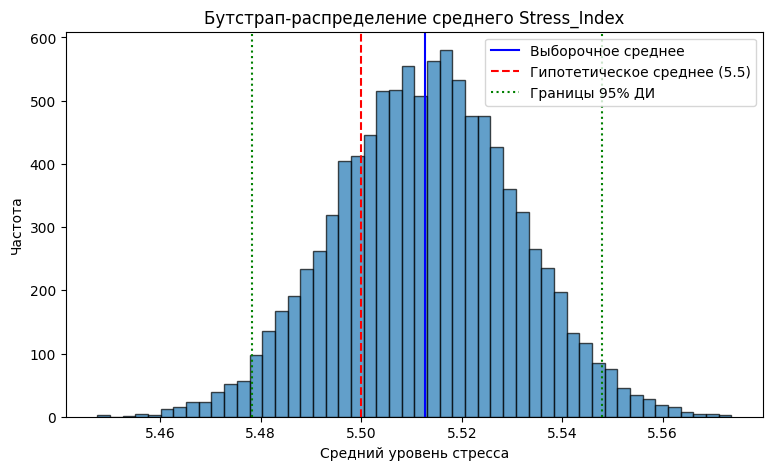

In [ ]:
rng = np.random.default_rng(42)

x = df_final['Stress_Index'].to_numpy()
mu0 = 5.5
alpha = 0.05
B = 10000
n = len(x)

obs_mean = x.mean()

boot_means = np.array([ rng.choice(x, size=n, replace=True).mean() for i in range(B)])

ci_low, ci_high = np.percentile( boot_means,  [100 * alpha / 2, 100 * (1 - alpha / 2)])

reject_h0 = not (ci_low <= mu0 <= ci_high)

print(f'Наблюдаемое среднее: {obs_mean:.4f}')
print(f'95% доверительный интервал: [{ci_low:.4f}; {ci_high:.4f}]')
print('Решение:', 'H0 отвергается' if reject_h0 else 'H0 не отвергается')

plt.figure(figsize=(9, 5))
plt.hist(boot_means, bins=50, edgecolor='black', alpha=0.7)

plt.axvline(obs_mean, color='blue', label='Выборочное среднее')

plt.axvline(mu0, color='red', linestyle='--', label='Гипотетическое среднее (5.5)')

plt.axvline(ci_low, color='green', linestyle=':', label='Границы 95% ДИ')
plt.axvline(ci_high, color='green', linestyle=':')

plt.title('Бутстрап-распределение среднего Stress_Index')
plt.xlabel('Средний уровень стресса')
plt.ylabel('Частота')
plt.legend(loc='best')
plt.show()

### Вывод по бутстрапу

По результатам бутстрапа выборочное среднее **Stress_Index** составляет **5.5127**, а 95%-й доверительный интервал — **[5.4783; 5.5479]**.

Поскольку гипотетическое значение **5.5** входит в доверительный интервал, на уровне значимости $\alpha=0.05$ **нулевая гипотеза не отвергается**. Статистически значимых отличий среднего уровня стресса от 5.5 не обнаружено.